# Zomato Restaurant Payout & Order Operations Database
## SQL Developer Colab

**Industry:** Food Delivery  
**Role:** SQL Developer  
**Runtime:** Google Colab  
**Database:** SQLite  
**Main skills:** Relational database design, internal API consumption, SQL reporting, transaction integrity, workflow automation, cron scheduling, and safe engineering practices.

**Business context:** Restaurant Finance Operations needs one SQL-led control database that connects completed orders, cancellations, commission deductions, discounts, promotional contributions, refunds, payout batches, and transfer records so payout calculations and operational exceptions can be reviewed consistently.

## How to Use This Notebook

1. Use **Runtime -> Run all**.
2. Wait until the setup prints **SETUP COMPLETE**.
3. Begin only after the large **SQL DEVELOPER WORK STARTS HERE** heading.
4. Edit only cells marked **SQL DEVELOPER WORKSPACE**.
5. Keep the provided TODO guidance, helper calls, and validation calls in place.
6. Unanswered workspaces return **Needs Review** rather than a runtime error, so the notebook remains safe to run from top to bottom.

## Operating Model

The SQL Developer consumes a temporary internal API, validates JSON, works with a normalized SQLite database, writes operational SQL, proves transaction behavior, designs the scheduled payout-summary workflow, and documents safe collaboration/change sequences. Python is prebuilt only for environment preparation, Dataset creation, API support, SQLite loading, validation, display, and diagrams.

## Review Window and Control Objective

- **Dataset period:** July 2026
- **Business review date:** 5 August 2026
- **Primary operational users:** Restaurant payout analysts, restaurant finance controllers, and payout reconciliation managers
- **Control objective:** Calculate restaurant payout value consistently and surface missing transfers, incorrect deductions, late transfers, duplicate references, refund-deduction errors, and overdue unpaid completed orders.

# 1. RUN THIS SETUP ONCE - DO NOT EDIT

All environment preparation, Dataset creation, temporary internal API code, JSON extraction, SQLite creation, validation helpers, and the restaurant payout control engine are prebuilt in this section.

## 1.1 Environment and Project Folder

In [ ]:
from __future__ import annotations

import hashlib
import json
import os
import random
import re
import shutil
import sqlite3
import subprocess
import sys
import threading
import time
from datetime import datetime, timedelta
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path
from urllib.parse import parse_qs, urlparse

import pandas as pd
import requests
from IPython.display import SVG, display

try:
    import graphviz
except Exception:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "graphviz"], check=True)
    import graphviz

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 20)
pd.set_option("display.width", 160)

PROJECT_ROOT = Path("/content/zomato_restaurant_payout_ops") if Path("/content").exists() else Path("/mnt/data/zomato_restaurant_payout_ops")
if PROJECT_ROOT.exists():
    shutil.rmtree(PROJECT_ROOT)
RAW_JSON_DIR = PROJECT_ROOT / "raw_json"
DATABASE_DIR = PROJECT_ROOT / "database"
REPORT_DIR = PROJECT_ROOT / "reports"
for folder in [PROJECT_ROOT, RAW_JSON_DIR, DATABASE_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 20260810
REVIEW_DATE = "2026-08-05"
print(f"Environment ready | Project folder: {PROJECT_ROOT} | Seed: {SEED}")

Environment ready | Project folder: /content/zomato_restaurant_payout_ops | Seed: 20260810


## 1.2 Dataset

The Dataset is created deterministically with a fixed seed and controlled operational anomalies. No manual upload or external data dependency is required.

In [ ]:
def generate_dataset(seed: int = 20260810):
    import random
    from datetime import datetime, timedelta
    import pandas as pd

    rng = random.Random(seed)
    cities = ["Bengaluru", "Mumbai", "Delhi NCR", "Hyderabad", "Pune"]
    cuisines = ["North Indian", "South Indian", "Biryani", "Chinese", "Fast Food", "Bakery", "Healthy", "Desserts"]
    brand_names = [
        "Spice Route", "Urban Tadka", "Green Bowl", "Royal Biryani", "Daily Dosa",
        "Tandoor Junction", "Wok Express", "Bake House", "Healthy Harvest", "Dessert Dock"
    ]
    plans = [
        ("STANDARD", 0.18, 0.18),
        ("GROWTH", 0.20, 0.18),
        ("PREMIUM", 0.15, 0.18),
        ("CLOUD_KITCHEN", 0.16, 0.18),
    ]
    commission_rules = pd.DataFrame([
        {"commission_plan": plan, "commission_rate": rate, "gst_rate": gst, "effective_from": "2026-01-01"}
        for plan, rate, gst in plans
    ])

    restaurants = []
    for i in range(1, 41):
        restaurants.append({
            "restaurant_id": f"RST{i:03d}",
            "restaurant_name": f"{brand_names[(i-1) % len(brand_names)]} {i:02d}",
            "city": cities[(i-1) % len(cities)],
            "cuisine": cuisines[(i*3) % len(cuisines)],
            "onboarding_date": (datetime(2024,1,1) + timedelta(days=(i*23) % 700)).date().isoformat(),
            "status": "PAUSED" if i in {11, 22, 33, 40} else "ACTIVE",
            "payout_cycle": "TWICE_WEEKLY" if i % 4 == 0 else "WEEKLY",
            "commission_plan": plans[(i-1) % 4][0],
        })
    restaurants = pd.DataFrame(restaurants)
    plan_rate = {plan: rate for plan, rate, _ in plans}

    orders = []
    period_start = datetime(2026, 7, 1)
    for i in range(1, 1001):
        restaurant = restaurants.iloc[rng.randrange(len(restaurants))]
        order_time = period_start + timedelta(days=rng.randrange(31), seconds=rng.randrange(86400))
        status_roll = rng.random()
        order_status = (
            "COMPLETED" if status_roll < 0.82 else
            "CANCELLED" if status_roll < 0.92 else
            "FAILED" if status_roll < 0.97 else "PENDING"
        )
        gross = round(rng.uniform(180, 2500), 2)
        delivery_charge = float(rng.choice([0, 20, 30, 40, 50, 60, 80, 100]))
        restaurant_discount = float(rng.choice([0, 0, 0, 20, 30, 50, 75, 100]))
        platform_discount = float(rng.choice([0, 0, 20, 40, 60, 80, 120]))
        restaurant_promo = float(rng.choice([0, 0, 0, 10, 20, 25, 50]))
        platform_promo = float(rng.choice([0, 0, 15, 25, 40, 60]))
        plan = restaurant["commission_plan"]
        rate = plan_rate[plan]

        if order_status == "COMPLETED":
            commission_base = max(0.0, gross - restaurant_discount)
            commission_amount = round(commission_base * rate, 2)
            gst_on_commission = round(commission_amount * 0.18, 2)
            restaurant_net = round(max(0.0, commission_base - commission_amount - gst_on_commission - restaurant_promo), 2)
        else:
            commission_amount = 0.0
            gst_on_commission = 0.0
            restaurant_net = 0.0

        payout_status = "NOT_ELIGIBLE"
        if order_status == "COMPLETED":
            payout_roll = rng.random()
            payout_status = "PAID" if payout_roll < 0.74 else "BATCHED" if payout_roll < 0.90 else "PENDING"

        cancelled_by = ""
        cancellation_reason = ""
        cancellation_compensation = 0.0
        if order_status == "CANCELLED":
            cancelled_by = rng.choice(["CUSTOMER", "RESTAURANT", "DELIVERY_PARTNER", "PLATFORM"])
            cancellation_reason = rng.choice([
                "Customer changed mind", "Restaurant unavailable", "Delivery capacity issue", "Address issue"
            ])
            if cancelled_by in {"CUSTOMER", "PLATFORM"}:
                cancellation_compensation = float(rng.choice([0, 0, 0, 50, 75, 100]))

        orders.append({
            "order_id": f"ORD{i:06d}",
            "restaurant_id": restaurant["restaurant_id"],
            "commission_plan": plan,
            "order_timestamp": order_time.strftime("%Y-%m-%d %H:%M:%S"),
            "payment_method": rng.choice(["UPI", "CARD", "CASH", "WALLET"]),
            "order_status": order_status,
            "gross_food_value": gross,
            "delivery_charge": delivery_charge,
            "restaurant_discount": restaurant_discount,
            "platform_discount": platform_discount,
            "restaurant_promo_contribution": restaurant_promo,
            "platform_promo_contribution": platform_promo,
            "commission_amount": commission_amount,
            "gst_on_commission": gst_on_commission,
            "restaurant_net_order_amount": restaurant_net,
            "payout_status": payout_status,
            "cancelled_by": cancelled_by,
            "cancellation_reason": cancellation_reason,
            "cancellation_compensation": cancellation_compensation,
            "created_at": order_time.strftime("%Y-%m-%d %H:%M:%S"),
        })
    orders = pd.DataFrame(orders)

    # Controlled anomaly 1: exactly 18 completed orders contain an incorrect commission deduction.
    completed_indices = orders.index[orders["order_status"].eq("COMPLETED")].tolist()
    for idx in completed_indices[:18]:
        commission_base = max(0.0, orders.at[idx, "gross_food_value"] - orders.at[idx, "restaurant_discount"])
        wrong_commission = round(commission_base * plan_rate[orders.at[idx, "commission_plan"]] + 2.50, 2)
        wrong_gst = round(wrong_commission * 0.18, 2)
        wrong_net = round(max(0.0, commission_base - wrong_commission - wrong_gst - orders.at[idx, "restaurant_promo_contribution"]), 2)
        orders.at[idx, "commission_amount"] = wrong_commission
        orders.at[idx, "gst_on_commission"] = wrong_gst
        orders.at[idx, "restaurant_net_order_amount"] = wrong_net

    # Controlled anomaly 2: exactly 45 older completed orders remain outside a payout batch.
    order_dates = pd.to_datetime(orders["order_timestamp"])
    old_completed = orders.index[
        (orders["order_status"] == "COMPLETED") & (order_dates.dt.date <= datetime(2026, 7, 30).date())
    ].tolist()
    overdue_indices = set(old_completed[:45])
    for idx in old_completed:
        if idx in overdue_indices:
            orders.at[idx, "payout_status"] = "PENDING"
        elif orders.at[idx, "payout_status"] == "PENDING":
            orders.at[idx, "payout_status"] = "BATCHED"

    # Refund events: completed, pending, and failed attempts.
    eligible_order_indices = orders.index[orders["order_status"].eq("COMPLETED")].tolist()
    refunds = []
    for j in range(110):
        idx = eligible_order_indices[(j * 7 + 13) % len(eligible_order_indices)]
        order = orders.loc[idx]
        refund_status = "COMPLETED" if j < 78 else "PENDING" if j < 96 else "FAILED"
        refund_amount = round(min(order["gross_food_value"] * 0.65, rng.uniform(30, max(31, order["gross_food_value"] * 0.5))), 2)
        refund_time = datetime.fromisoformat(order["order_timestamp"]) + timedelta(days=1 + (j % 4), hours=j % 6)
        refunds.append({
            "refund_id": f"RFD{j+1:05d}",
            "order_id": order["order_id"],
            "refund_timestamp": refund_time.strftime("%Y-%m-%d %H:%M:%S"),
            "refund_amount": refund_amount,
            "refund_status": refund_status,
            "reason": rng.choice(["Item missing", "Quality issue", "Order correction", "Customer support adjustment"]),
        })
    refunds = pd.DataFrame(refunds)
    completed_refund_by_order = (
        refunds[refunds["refund_status"] == "COMPLETED"].groupby("order_id")["refund_amount"].sum().to_dict()
    )

    payout_periods = [(1, 7), (8, 14), (15, 21), (22, 31)]
    payout_batches = []
    payout_items = []
    parsed_order_dates = pd.to_datetime(orders["order_timestamp"])
    for _, restaurant in restaurants.iterrows():
        for period_no, (day_start, day_end) in enumerate(payout_periods, 1):
            mask = (
                (orders["restaurant_id"] == restaurant["restaurant_id"]) &
                (orders["order_status"] == "COMPLETED") &
                (orders["payout_status"].isin(["PAID", "BATCHED"])) &
                parsed_order_dates.dt.day.between(day_start, day_end)
            )
            period_orders = orders[mask].sort_values("order_id")
            if period_orders.empty:
                continue
            payout_id = f"PAY-{restaurant['restaurant_id']}-{period_no:02d}"
            payout_date = (datetime(2026, 7, day_end) + timedelta(days=2)).date().isoformat()
            for _, order in period_orders.iterrows():
                refund_adjustment = round(completed_refund_by_order.get(order["order_id"], 0.0), 2)
                payout_items.append({
                    "payout_id": payout_id,
                    "order_id": order["order_id"],
                    "included_order_amount": order["restaurant_net_order_amount"],
                    "refund_adjustment": refund_adjustment,
                    "cancellation_adjustment": 0.0,
                    "net_payout_item_amount": round(max(0.0, order["restaurant_net_order_amount"] - refund_adjustment), 2),
                })
            payout_batches.append({
                "payout_id": payout_id,
                "restaurant_id": restaurant["restaurant_id"],
                "payout_date": payout_date,
                "period_start": f"2026-07-{day_start:02d}",
                "period_end": f"2026-07-{day_end:02d}",
                "expected_payout_amount": 0.0,
                "payout_status": "READY",
                "bank_reference": f"ZOM-PAY-{restaurant['restaurant_id']}-{period_no:02d}",
            })
    payout_items = pd.DataFrame(payout_items)
    payout_batches = pd.DataFrame(payout_batches)

    # Controlled anomaly 3: exactly eight payout items contain an incorrect completed-refund deduction.
    refund_item_indexes = payout_items.index[payout_items["refund_adjustment"].gt(0)].tolist()
    for idx in refund_item_indexes[:8]:
        payout_items.at[idx, "refund_adjustment"] = round(max(0.0, payout_items.at[idx, "refund_adjustment"] - 7.0), 2)
        payout_items.at[idx, "net_payout_item_amount"] = round(
            max(0.0, payout_items.at[idx, "included_order_amount"] - payout_items.at[idx, "refund_adjustment"]), 2
        )

    payout_totals = payout_items.groupby("payout_id")["net_payout_item_amount"].sum().round(2)
    payout_batches["expected_payout_amount"] = payout_batches["payout_id"].map(payout_totals).fillna(0).round(2)

    payout_transfers = []
    for i, payout in payout_batches.sort_values("payout_id").reset_index(drop=True).iterrows():
        payout_transfers.append({
            "transfer_id": f"TRF{i+1:05d}",
            "payout_id": payout["payout_id"],
            "restaurant_id": payout["restaurant_id"],
            "transfer_date": payout["payout_date"],
            "transferred_amount": payout["expected_payout_amount"],
            "bank_reference": f"BANK-ZOM-{i+1:05d}",
            "transfer_status": "SUCCESS",
        })
    payout_transfers = pd.DataFrame(payout_transfers)

    sorted_payout_ids = payout_batches.sort_values("payout_id")["payout_id"].tolist()
    missing_transfer_ids = set(sorted_payout_ids[:10])
    amount_mismatch_ids = set(sorted_payout_ids[10:22])
    late_transfer_ids = set(sorted_payout_ids[22:31])
    duplicate_pair_ids = sorted_payout_ids[31:39]

    # Controlled anomaly 4: ten payout batches have no transfer record.
    payout_transfers = payout_transfers[~payout_transfers["payout_id"].isin(missing_transfer_ids)].reset_index(drop=True)

    # Controlled anomaly 5: twelve payout transfers have amount mismatches.
    for payout_id in amount_mismatch_ids:
        idx = payout_transfers.index[payout_transfers["payout_id"] == payout_id][0]
        payout_transfers.at[idx, "transferred_amount"] = round(
            payout_transfers.at[idx, "transferred_amount"] + (25.0 if idx % 2 == 0 else -18.0), 2
        )

    # Controlled anomaly 6: nine transfers arrive four days after the planned payout date.
    for payout_id in late_transfer_ids:
        idx = payout_transfers.index[payout_transfers["payout_id"] == payout_id][0]
        payout_transfers.at[idx, "transfer_date"] = (
            datetime.fromisoformat(payout_transfers.at[idx, "transfer_date"]) + timedelta(days=4)
        ).date().isoformat()

    # Controlled anomaly 7: four duplicate bank-reference groups.
    for pair_no in range(4):
        payout_a, payout_b = duplicate_pair_ids[2 * pair_no], duplicate_pair_ids[2 * pair_no + 1]
        idx_a = payout_transfers.index[payout_transfers["payout_id"] == payout_a][0]
        idx_b = payout_transfers.index[payout_transfers["payout_id"] == payout_b][0]
        shared_reference = f"DUP-ZOM-{pair_no+1:02d}"
        payout_transfers.at[idx_a, "bank_reference"] = shared_reference
        payout_transfers.at[idx_b, "bank_reference"] = shared_reference

    payout_batches.loc[payout_batches["payout_id"].isin(missing_transfer_ids), "payout_status"] = "OPEN"
    payout_batches.loc[~payout_batches["payout_id"].isin(missing_transfer_ids), "payout_status"] = "TRANSFERRED"

    controls = {
        "missing_transfer_ids": sorted(missing_transfer_ids),
        "amount_mismatch_ids": sorted(amount_mismatch_ids),
        "late_transfer_ids": sorted(late_transfer_ids),
        "duplicate_pair_ids": duplicate_pair_ids,
        "review_date": "2026-08-05",
    }
    return {
        "restaurants": restaurants,
        "commission_rules": commission_rules,
        "orders": orders,
        "refunds": refunds,
        "payout_batches": payout_batches,
        "payout_items": payout_items,
        "payout_transfers": payout_transfers,
        "controls": controls,
    }


DATA = generate_dataset(SEED)
restaurants_df = DATA["restaurants"]
commission_rules_df = DATA["commission_rules"]
orders_df = DATA["orders"]
refunds_df = DATA["refunds"]
payout_batches_df = DATA["payout_batches"]
payout_items_df = DATA["payout_items"]
payout_transfers_df = DATA["payout_transfers"]

def _dataset_signature(frames):
    h = hashlib.sha256()
    for name in sorted(frames):
        h.update(name.encode("utf-8"))
        h.update(frames[name].to_csv(index=False).encode("utf-8"))
    return h.hexdigest()

DATASET_SIGNATURE = _dataset_signature({
    "restaurants": restaurants_df,
    "commission_rules": commission_rules_df,
    "orders": orders_df,
    "refunds": refunds_df,
    "payout_batches": payout_batches_df,
    "payout_items": payout_items_df,
    "payout_transfers": payout_transfers_df,
})
dataset_counts = pd.DataFrame([
    ["restaurants", len(restaurants_df)],
    ["commission_rules", len(commission_rules_df)],
    ["orders", len(orders_df)],
    ["refunds", len(refunds_df)],
    ["payout_batches", len(payout_batches_df)],
    ["payout_items", len(payout_items_df)],
    ["payout_transfers", len(payout_transfers_df)],
], columns=["Dataset resource", "Rows"])
display(dataset_counts)
print("Dataset signature:", DATASET_SIGNATURE)

,Dataset resource,Rows
0,restaurants,40
1,commission_rules,4
2,orders,1000
3,refunds,110
4,payout_batches,158
5,payout_items,766
6,payout_transfers,148


Dataset signature: 255112fee75bf41bed836c21aea9ea011782cae5bac4fdbc31e88f6d1a3bae4a


## 1.3 Temporary Internal API

The API is created inside the runtime. The SQL Developer consumes it but does not build or modify the server.

In [ ]:
if "api_server" in globals():
    try:
        api_server.shutdown()
        api_server.server_close()
    except Exception:
        pass

API_DATA = {
    "restaurants": restaurants_df.to_dict("records"),
    "orders": orders_df.to_dict("records"),
    "refunds": refunds_df.to_dict("records"),
    "payouts": payout_batches_df.to_dict("records"),
    "payout_items": payout_items_df.to_dict("records"),
    "payout_transfers": payout_transfers_df.to_dict("records"),
}
ORDER_FIELDS = list(orders_df.columns)

class InternalAPIHandler(BaseHTTPRequestHandler):
    def log_message(self, format, *args):
        return

    def _send_json(self, status, payload):
        raw = json.dumps(payload, default=str).encode("utf-8")
        self.send_response(status)
        self.send_header("Content-Type", "application/json")
        self.send_header("Content-Length", str(len(raw)))
        self.end_headers()
        self.wfile.write(raw)

    def _read_json(self):
        length = int(self.headers.get("Content-Length", "0"))
        try:
            return json.loads(self.rfile.read(length).decode("utf-8")) if length else {}
        except Exception:
            return None

    def do_GET(self):
        parsed = urlparse(self.path)
        path = parsed.path.strip("/")
        params = {k: v[-1] for k, v in parse_qs(parsed.query).items()}
        if path == "health":
            return self._send_json(200, {"status": "ok"})
        parts = path.split("/") if path else []
        if not parts or parts[0] not in API_DATA:
            return self._send_json(404, {"error": "resource not found"})
        resource = parts[0]
        if len(parts) == 2:
            if resource != "orders":
                return self._send_json(404, {"error": "record endpoint not available"})
            record = next((x for x in API_DATA["orders"] if x["order_id"] == parts[1]), None)
            return self._send_json(200, record) if record else self._send_json(404, {"error": "order not found"})

        records = list(API_DATA[resource])
        for key, value in params.items():
            if key in {"limit", "offset"}:
                continue
            records = [r for r in records if str(r.get(key)) == str(value)]
        offset = int(params.get("offset", 0))
        limit = int(params.get("limit", 200))
        page = records[offset:offset+limit]
        return self._send_json(200, {"records": page, "count": len(page), "total": len(records), "offset": offset, "limit": limit})

    def do_POST(self):
        if urlparse(self.path).path != "/orders":
            return self._send_json(404, {"error": "resource not found"})
        payload = self._read_json()
        if payload is None or set(payload.keys()) != set(ORDER_FIELDS):
            return self._send_json(400, {"error": "complete order payload required"})
        if any(x["order_id"] == payload["order_id"] for x in API_DATA["orders"]):
            return self._send_json(409, {"error": "order already exists"})
        API_DATA["orders"].append(payload)
        return self._send_json(201, payload)

    def do_PUT(self):
        parts = urlparse(self.path).path.strip("/").split("/")
        if len(parts) != 2 or parts[0] != "orders":
            return self._send_json(404, {"error": "resource not found"})
        payload = self._read_json()
        if payload is None or set(payload.keys()) != set(ORDER_FIELDS) or payload.get("order_id") != parts[1]:
            return self._send_json(400, {"error": "complete replacement payload required"})
        for i, record in enumerate(API_DATA["orders"]):
            if record["order_id"] == parts[1]:
                API_DATA["orders"][i] = payload
                return self._send_json(200, payload)
        return self._send_json(404, {"error": "order not found"})

    def do_PATCH(self):
        parts = urlparse(self.path).path.strip("/").split("/")
        if len(parts) != 2 or parts[0] != "orders":
            return self._send_json(404, {"error": "resource not found"})
        payload = self._read_json()
        if payload is None or not payload or "order_id" in payload or any(k not in ORDER_FIELDS for k in payload):
            return self._send_json(400, {"error": "invalid patch payload"})
        for record in API_DATA["orders"]:
            if record["order_id"] == parts[1]:
                record.update(payload)
                return self._send_json(200, record)
        return self._send_json(404, {"error": "order not found"})

    def do_DELETE(self):
        parts = urlparse(self.path).path.strip("/").split("/")
        if len(parts) != 2 or parts[0] != "orders":
            return self._send_json(404, {"error": "resource not found"})
        for i, record in enumerate(API_DATA["orders"]):
            if record["order_id"] == parts[1]:
                deleted = API_DATA["orders"].pop(i)
                return self._send_json(200, deleted)
        return self._send_json(404, {"error": "order not found"})

api_server = ThreadingHTTPServer(("127.0.0.1", 0), InternalAPIHandler)
api_thread = threading.Thread(target=api_server.serve_forever, daemon=True)
api_thread.start()
BASE_URL = f"http://127.0.0.1:{api_server.server_address[1]}"
health = requests.get(f"{BASE_URL}/health", timeout=5)
print(f"Temporary internal API ready: {BASE_URL} | health={health.status_code}")

Temporary internal API ready: http://127.0.0.1:37723 | health=200


### Internal API endpoint documentation

| Method | Endpoint | Purpose | Expected status |
|---|---|---|---|
| GET | `/restaurants` | Read restaurant master records | 200 |
| GET | `/orders` | Read orders with filters and pagination | 200 |
| GET | `/orders/{id}` | Read one order | 200 / 404 |
| POST | `/orders` | Create one order record | 201 / 400 / 409 |
| PUT | `/orders/{id}` | Completely replace one order record | 200 / 400 / 404 |
| PATCH | `/orders/{id}` | Update selected order fields | 200 / 400 / 404 |
| DELETE | `/orders/{id}` | Delete one order record | 200 / 404 |
| GET | `/refunds` | Read refund events | 200 |
| GET | `/payouts` | Read restaurant payout batches | 200 |
| GET | `/payout_items` | Read order-to-payout mappings | 200 |
| GET | `/payout_transfers` | Read payout transfer records | 200 |

The SQL Developer consumes these endpoints. The API service itself is prebuilt in setup.

## 1.4 API Extraction and Dataset Validation

Each resource is fetched with `requests`, raw JSON is saved locally, required fields and primary keys are validated, and ingestion metadata is prepared.

In [ ]:
API_RESOURCES = ["restaurants", "orders", "refunds", "payouts", "payout_items", "payout_transfers"]
DATA_CONTRACTS = {
    "restaurants": ["restaurant_id", "restaurant_name", "city", "cuisine", "onboarding_date", "status", "payout_cycle", "commission_plan"],
    "orders": ORDER_FIELDS,
    "refunds": ["refund_id", "order_id", "refund_timestamp", "refund_amount", "refund_status", "reason"],
    "payouts": ["payout_id", "restaurant_id", "payout_date", "period_start", "period_end", "expected_payout_amount", "payout_status", "bank_reference"],
    "payout_items": ["payout_id", "order_id", "included_order_amount", "refund_adjustment", "cancellation_adjustment", "net_payout_item_amount"],
    "payout_transfers": ["transfer_id", "payout_id", "restaurant_id", "transfer_date", "transferred_amount", "bank_reference", "transfer_status"],
}
PRIMARY_KEYS = {"restaurants": ["restaurant_id"], "orders": ["order_id"], "refunds": ["refund_id"], "payouts": ["payout_id"], "payout_items": ["payout_id", "order_id"], "payout_transfers": ["transfer_id"]}

def fetch_all(resource, page_size=200):
    records, offset = [], 0
    started = datetime.now()
    while True:
        response = requests.get(f"{BASE_URL}/{resource}", params={"limit": page_size, "offset": offset}, timeout=5)
        response.raise_for_status()
        payload = response.json()
        batch = payload["records"]
        records.extend(batch)
        if len(batch) < page_size:
            break
        offset += page_size
    completed = datetime.now()
    return records, {
        "run_id": f"ING-{resource.upper()}-001", "endpoint": f"/{resource}",
        "started_at": started.strftime("%Y-%m-%d %H:%M:%S"), "completed_at": completed.strftime("%Y-%m-%d %H:%M:%S"),
        "rows_received": len(records), "rows_loaded": len(records), "status": "SUCCESS", "error_message": ""
    }

extracted = {}
ingestion_rows = []
quality_rows = []
for resource in API_RESOURCES:
    records, run = fetch_all(resource)
    (RAW_JSON_DIR / f"{resource}.json").write_text(json.dumps(records, indent=2), encoding="utf-8")
    frame = pd.DataFrame(records)
    missing_cols = [c for c in DATA_CONTRACTS[resource] if c not in frame.columns]
    key_nulls = int(frame[PRIMARY_KEYS[resource]].isna().any(axis=1).sum()) if not frame.empty else 0
    key_duplicates = int(frame.duplicated(PRIMARY_KEYS[resource]).sum()) if not frame.empty else 0
    contract_ok = not missing_cols and key_nulls == 0 and key_duplicates == 0
    if not contract_ok:
        raise ValueError(f"Dataset contract failed for {resource}: missing={missing_cols}, null_keys={key_nulls}, duplicate_keys={key_duplicates}")
    extracted[resource] = frame
    ingestion_rows.append(run)
    quality_rows.append([resource, len(frame), len(missing_cols), key_nulls, key_duplicates, "Passed"])

api_ingestion_df = pd.DataFrame(ingestion_rows)
data_quality_summary = pd.DataFrame(quality_rows, columns=["Resource", "Rows", "Missing columns", "Null keys", "Duplicate keys", "Status"])
display(data_quality_summary)
print(f"Raw JSON files saved: {len(list(RAW_JSON_DIR.glob('*.json')))}")

,Resource,Rows,Missing columns,Null keys,Duplicate keys,Status
0,restaurants,40,0,0,0,Passed
1,orders,1000,0,0,0,Passed
2,refunds,110,0,0,0,Passed
3,payouts,158,0,0,0,Passed
4,payout_items,766,0,0,0,Passed
5,payout_transfers,148,0,0,0,Passed


Raw JSON files saved: 6


## 1.5 SQLite Database Creation

The normalized database uses seven core tables, three system-managed tables, foreign keys, CHECK constraints, a composite primary key, and practical indexes.

In [ ]:
DB_PATH = DATABASE_DIR / "zomato_restaurant_payout_ops.db"
if DB_PATH.exists():
    DB_PATH.unlink()
conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON;")
conn.executescript(r"""
CREATE TABLE restaurants (
  restaurant_id TEXT PRIMARY KEY NOT NULL,
  restaurant_name TEXT NOT NULL,
  city TEXT NOT NULL,
  cuisine TEXT NOT NULL,
  onboarding_date TEXT NOT NULL,
  status TEXT NOT NULL CHECK(status IN ('ACTIVE','PAUSED','INACTIVE')),
  payout_cycle TEXT NOT NULL CHECK(payout_cycle IN ('WEEKLY','TWICE_WEEKLY')),
  commission_plan TEXT NOT NULL
);
CREATE TABLE commission_rules (
  commission_plan TEXT PRIMARY KEY NOT NULL,
  commission_rate REAL NOT NULL CHECK(commission_rate >= 0 AND commission_rate <= 1),
  gst_rate REAL NOT NULL CHECK(gst_rate >= 0 AND gst_rate <= 1),
  effective_from TEXT NOT NULL
);
CREATE TABLE orders (
  order_id TEXT PRIMARY KEY NOT NULL,
  restaurant_id TEXT NOT NULL,
  commission_plan TEXT NOT NULL,
  order_timestamp TEXT NOT NULL,
  payment_method TEXT NOT NULL CHECK(payment_method IN ('UPI','CARD','CASH','WALLET')),
  order_status TEXT NOT NULL CHECK(order_status IN ('COMPLETED','CANCELLED','FAILED','PENDING')),
  gross_food_value REAL NOT NULL CHECK(gross_food_value >= 0),
  delivery_charge REAL NOT NULL CHECK(delivery_charge >= 0),
  restaurant_discount REAL NOT NULL CHECK(restaurant_discount >= 0),
  platform_discount REAL NOT NULL CHECK(platform_discount >= 0),
  restaurant_promo_contribution REAL NOT NULL CHECK(restaurant_promo_contribution >= 0),
  platform_promo_contribution REAL NOT NULL CHECK(platform_promo_contribution >= 0),
  commission_amount REAL NOT NULL CHECK(commission_amount >= 0),
  gst_on_commission REAL NOT NULL CHECK(gst_on_commission >= 0),
  restaurant_net_order_amount REAL NOT NULL CHECK(restaurant_net_order_amount >= 0),
  payout_status TEXT NOT NULL CHECK(payout_status IN ('PAID','BATCHED','PENDING','NOT_ELIGIBLE')),
  cancelled_by TEXT NOT NULL DEFAULT '',
  cancellation_reason TEXT NOT NULL DEFAULT '',
  cancellation_compensation REAL NOT NULL CHECK(cancellation_compensation >= 0),
  created_at TEXT NOT NULL,
  FOREIGN KEY(restaurant_id) REFERENCES restaurants(restaurant_id),
  FOREIGN KEY(commission_plan) REFERENCES commission_rules(commission_plan)
);
CREATE TABLE refunds (
  refund_id TEXT PRIMARY KEY NOT NULL,
  order_id TEXT NOT NULL,
  refund_timestamp TEXT NOT NULL,
  refund_amount REAL NOT NULL CHECK(refund_amount > 0),
  refund_status TEXT NOT NULL CHECK(refund_status IN ('COMPLETED','PENDING','FAILED')),
  reason TEXT NOT NULL,
  FOREIGN KEY(order_id) REFERENCES orders(order_id)
);
CREATE TABLE payout_batches (
  payout_id TEXT PRIMARY KEY NOT NULL,
  restaurant_id TEXT NOT NULL,
  payout_date TEXT NOT NULL,
  period_start TEXT NOT NULL,
  period_end TEXT NOT NULL,
  expected_payout_amount REAL NOT NULL CHECK(expected_payout_amount >= 0),
  payout_status TEXT NOT NULL CHECK(payout_status IN ('READY','OPEN','TRANSFERRED','FAILED')),
  bank_reference TEXT NOT NULL,
  FOREIGN KEY(restaurant_id) REFERENCES restaurants(restaurant_id)
);
CREATE TABLE payout_items (
  payout_id TEXT NOT NULL,
  order_id TEXT NOT NULL,
  included_order_amount REAL NOT NULL CHECK(included_order_amount >= 0),
  refund_adjustment REAL NOT NULL CHECK(refund_adjustment >= 0),
  cancellation_adjustment REAL NOT NULL CHECK(cancellation_adjustment >= 0),
  net_payout_item_amount REAL NOT NULL CHECK(net_payout_item_amount >= 0),
  PRIMARY KEY(payout_id, order_id),
  FOREIGN KEY(payout_id) REFERENCES payout_batches(payout_id),
  FOREIGN KEY(order_id) REFERENCES orders(order_id)
);
CREATE TABLE payout_transfers (
  transfer_id TEXT PRIMARY KEY NOT NULL,
  payout_id TEXT NOT NULL,
  restaurant_id TEXT NOT NULL,
  transfer_date TEXT NOT NULL,
  transferred_amount REAL NOT NULL CHECK(transferred_amount >= 0),
  bank_reference TEXT NOT NULL,
  transfer_status TEXT NOT NULL CHECK(transfer_status IN ('SUCCESS','FAILED','PENDING')),
  FOREIGN KEY(payout_id) REFERENCES payout_batches(payout_id),
  FOREIGN KEY(restaurant_id) REFERENCES restaurants(restaurant_id)
);
CREATE TABLE restaurant_ledger (
  ledger_id TEXT PRIMARY KEY NOT NULL,
  restaurant_id TEXT NOT NULL,
  source_type TEXT NOT NULL,
  source_id TEXT NOT NULL,
  entry_timestamp TEXT NOT NULL,
  amount REAL NOT NULL CHECK(amount <> 0),
  entry_status TEXT NOT NULL CHECK(entry_status IN ('POSTED','PENDING','REVERSED')),
  description TEXT NOT NULL,
  FOREIGN KEY(restaurant_id) REFERENCES restaurants(restaurant_id)
);
CREATE TABLE payout_exceptions (
  exception_id TEXT PRIMARY KEY NOT NULL,
  restaurant_id TEXT NOT NULL,
  entity_type TEXT NOT NULL,
  entity_id TEXT NOT NULL,
  exception_type TEXT NOT NULL,
  severity TEXT NOT NULL CHECK(severity IN ('LOW','MEDIUM','HIGH','CRITICAL')),
  expected_value REAL,
  actual_value REAL,
  status TEXT NOT NULL CHECK(status IN ('OPEN','RESOLVED')),
  detected_at TEXT NOT NULL,
  details TEXT NOT NULL,
  FOREIGN KEY(restaurant_id) REFERENCES restaurants(restaurant_id)
);
CREATE TABLE api_ingestion_runs (
  run_id TEXT PRIMARY KEY NOT NULL,
  endpoint TEXT NOT NULL,
  started_at TEXT NOT NULL,
  completed_at TEXT NOT NULL,
  rows_received INTEGER NOT NULL CHECK(rows_received >= 0),
  rows_loaded INTEGER NOT NULL CHECK(rows_loaded >= 0),
  status TEXT NOT NULL CHECK(status IN ('SUCCESS','FAILED')),
  error_message TEXT NOT NULL DEFAULT ''
);
CREATE INDEX idx_orders_restaurant_time ON orders(restaurant_id, order_timestamp);
CREATE INDEX idx_orders_status ON orders(order_status, payout_status);
CREATE INDEX idx_orders_payment_method ON orders(payment_method, order_status);
CREATE INDEX idx_refunds_order_status ON refunds(order_id, refund_status);
CREATE INDEX idx_payout_restaurant_date ON payout_batches(restaurant_id, payout_date);
CREATE INDEX idx_payout_status ON payout_batches(payout_status);
CREATE INDEX idx_payout_items_order ON payout_items(order_id);
CREATE INDEX idx_transfer_payout_status ON payout_transfers(payout_id, transfer_status);
CREATE INDEX idx_transfer_bank_reference ON payout_transfers(bank_reference);
CREATE INDEX idx_exception_status ON payout_exceptions(status, severity, exception_type);
""")
print("SQLite schema created | foreign_keys=", conn.execute("PRAGMA foreign_keys").fetchone()[0], "| core tables=7 | system-managed tables=3")

SQLite schema created | foreign_keys= 1 | core tables=7 | system-managed tables=3


In [ ]:
commission_rules_df.to_sql("commission_rules", conn, if_exists="append", index=False)
extracted["restaurants"].to_sql("restaurants", conn, if_exists="append", index=False)
extracted["orders"].to_sql("orders", conn, if_exists="append", index=False)
extracted["refunds"].to_sql("refunds", conn, if_exists="append", index=False)
extracted["payouts"].to_sql("payout_batches", conn, if_exists="append", index=False)
extracted["payout_items"].to_sql("payout_items", conn, if_exists="append", index=False)
extracted["payout_transfers"].to_sql("payout_transfers", conn, if_exists="append", index=False)
api_ingestion_df.to_sql("api_ingestion_runs", conn, if_exists="append", index=False)
conn.commit()

sqlite_counts = pd.read_sql_query("""
  SELECT 'restaurants' AS table_name, COUNT(*) AS row_count FROM restaurants
  UNION ALL SELECT 'commission_rules', COUNT(*) FROM commission_rules
  UNION ALL SELECT 'orders', COUNT(*) FROM orders
  UNION ALL SELECT 'refunds', COUNT(*) FROM refunds
  UNION ALL SELECT 'payout_batches', COUNT(*) FROM payout_batches
  UNION ALL SELECT 'payout_items', COUNT(*) FROM payout_items
  UNION ALL SELECT 'payout_transfers', COUNT(*) FROM payout_transfers
  UNION ALL SELECT 'api_ingestion_runs', COUNT(*) FROM api_ingestion_runs
""", conn)
display(sqlite_counts)
fk_violations = conn.execute("PRAGMA foreign_key_check").fetchall()
print("Foreign-key validation:", "Passed" if not fk_violations else f"Needs Review ({len(fk_violations)} violations)")

,table_name,row_count
0,restaurants,40
1,commission_rules,4
2,orders,1000
3,refunds,110
4,payout_batches,158
5,payout_items,766
6,payout_transfers,148
7,api_ingestion_runs,6


Foreign-key validation: Passed


## 1.6 SQL Developer Validation and Visualization Helpers

These helpers run SQL, validate stable outputs, check API behavior, validate the ER design, prove transactions, validate cron expressions, track activity status, and render diagrams.

In [ ]:
ACTIVITY_IDS = ['ER-1', 'API-Q1', 'API-Q2', 'API-Q3', 'API-Q4', 'API-Q5', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10', 'Q11', 'Q12', 'Q13', 'T1', 'T2', 'AUTO-FLOW', 'AUTO-REPORT', 'AUTO-CRON', 'ENG-GIT', 'ENG-CHANGE']
activity_status = {activity_id: "Needs Review" for activity_id in ACTIVITY_IDS}
EXPECTED_SQL_META = {'Q1': {'columns': ['order_id', 'restaurant_name', 'city', 'payment_method', 'gross_food_value', 'restaurant_net_order_amount', 'order_timestamp'], 'row_count': 10, 'first_row': {'order_id': 'ORD000526', 'restaurant_name': 'Wok Express 07', 'city': 'Mumbai', 'payment_method': 'CARD', 'gross_food_value': 2474.34, 'restaurant_net_order_amount': 2036.38, 'order_timestamp': '2026-07-01 04:00:13'}, 'hash': 'a5405979eb458db4c02bb429bccfee99116549c76274151fc0bb042df9980ca7'}, 'Q2': {'columns': ['restaurant_id', 'restaurant_name', 'city', 'completed_orders', 'gross_food_value', 'net_order_value'], 'row_count': 37, 'first_row': {'restaurant_id': 'RST033', 'restaurant_name': 'Green Bowl 33', 'city': 'Delhi NCR', 'completed_orders': 38, 'gross_food_value': 47217.09, 'net_order_value': 35838.12}, 'hash': '0ba3a0f3d92747ee6270b6530c05e12c0017229475a41acaa8e75a3ffeedf25a'}, 'Q3': {'columns': ['payout_id', 'restaurant_name', 'payout_date', 'expected_payout_amount', 'transferred_amount', 'variance', 'reconciliation_status'], 'row_count': 158, 'first_row': {'payout_id': 'PAY-RST001-03', 'restaurant_name': 'Spice Route 01', 'payout_date': '2026-07-23', 'expected_payout_amount': 10743.55, 'transferred_amount': 0.0, 'variance': -10743.55, 'reconciliation_status': 'MISSING'}, 'hash': '56323b4d90cbb07713e1225d1d30c15faa0ed816819cc73d6e633b3eaa535355'}, 'Q4': {'columns': ['payout_id', 'restaurant_id', 'restaurant_name', 'payout_date', 'expected_payout_amount', 'bank_reference'], 'row_count': 10, 'first_row': {'payout_id': 'PAY-RST001-03', 'restaurant_id': 'RST001', 'restaurant_name': 'Spice Route 01', 'payout_date': '2026-07-23', 'expected_payout_amount': 10743.55, 'bank_reference': 'ZOM-PAY-RST001-03'}, 'hash': '7c394b3f6b2db9f222725872829b2ba121ba40fa92594d9a003881ea566ed06c'}, 'Q5': {'columns': ['restaurant_id', 'restaurant_name', 'city', 'cuisine'], 'row_count': 28, 'first_row': {'restaurant_id': 'RST001', 'restaurant_name': 'Spice Route 01', 'city': 'Bengaluru', 'cuisine': 'Chinese'}, 'hash': '964ada9149ea38fb2f1ffef7aec79c58c2bf688c300c8629af1974f43bbcf50a'}, 'Q6': {'columns': ['restaurant_id', 'restaurant_name_upper', 'city_code', 'days_since_last_completed_order', 'open_exceptions', 'finance_risk_band'], 'row_count': 40, 'first_row': {'restaurant_id': 'RST001', 'restaurant_name_upper': 'SPICE ROUTE 01', 'city_code': 'Ben', 'days_since_last_completed_order': 5, 'open_exceptions': 9, 'finance_risk_band': 'HIGH'}, 'hash': '426ddabe466ca28e076a9f9fb561c0e6630064b46f15cdbf2b16ffaaec0ccc7b'}, 'Q7': {'columns': ['restaurant_id', 'restaurant_name', 'city', 'avg_completed_order_value'], 'row_count': 21, 'first_row': {'restaurant_id': 'RST036', 'restaurant_name': 'Tandoor Junction 36', 'city': 'Bengaluru', 'avg_completed_order_value': 1275.39}, 'hash': 'd017c57493ada50f3a9f346bdc33731588d0181232b6ba41f10d816ea910dca6'}, 'Q8': {'columns': ['payout_id', 'restaurant_id', 'recorded_payout_amount', 'recalculated_payout_amount', 'transferred_amount', 'calculation_variance', 'calculation_status'], 'row_count': 158, 'first_row': {'payout_id': 'PAY-RST001-03', 'restaurant_id': 'RST001', 'recorded_payout_amount': 10743.55, 'recalculated_payout_amount': 10722.55, 'transferred_amount': 0.0, 'calculation_variance': 21.0, 'calculation_status': 'CALC_REVIEW'}, 'hash': '73c018ba230f122867a9bc691e188c7f696604828aed1606db348fab96b890c8'}, 'Q9': {'columns': ['restaurant_id', 'restaurant_name', 'city', 'completed_net_value', 'city_rank'], 'row_count': 40, 'first_row': {'restaurant_id': 'RST036', 'restaurant_name': 'Tandoor Junction 36', 'city': 'Bengaluru', 'completed_net_value': 33160.11, 'city_rank': 1}, 'hash': '6615483af5fc51154d375908f320a4c5bfed060d86c42ce75d3bbbab7472b9c8'}, 'Q10': {'columns': ['order_date', 'daily_net_value', 'running_net_value', 'seven_day_moving_average'], 'row_count': 31, 'first_row': {'order_date': '2026-07-01', 'daily_net_value': 29153.68, 'running_net_value': 29153.68, 'seven_day_moving_average': 29153.68}, 'hash': '8545f0b2f317d7328a7f1f72ef383b7f9df3fd5a7cff7d937cc155b6648933c3'}, 'Q11': {'columns': ['order_date', 'daily_net_value', 'previous_day_value', 'day_over_day_change', 'day_over_day_pct'], 'row_count': 31, 'first_row': {'order_date': '2026-07-01', 'daily_net_value': 29153.68, 'previous_day_value': None, 'day_over_day_change': None, 'day_over_day_pct': None}, 'hash': '6c7072c4d175988ff6426d9986992d8d89203e6843db15985dd052e3f0786aa3'}, 'Q12': {'columns': ['restaurant_id', 'restaurant_name', 'first_completed_order_id', 'first_completed_order_timestamp', 'latest_completed_order_id', 'latest_completed_order_timestamp'], 'row_count': 40, 'first_row': {'restaurant_id': 'RST001', 'restaurant_name': 'Spice Route 01', 'first_completed_order_id': 'ORD000564', 'first_completed_order_timestamp': '2026-07-02 08:23:11', 'latest_completed_order_id': 'ORD000033', 'latest_completed_order_timestamp': '2026-07-31 19:25:20'}, 'hash': '19c8ff04267c90792a14f37ab8d5ec333713a6b93c38ab2bdd957817fa142006'}, 'Q13': {'columns': ['city', 'restaurant_id', 'exception_type', 'exception_count', 'exception_rank'], 'row_count': 42, 'first_row': {'city': 'Bengaluru', 'restaurant_id': 'RST001', 'exception_type': 'MISSING_PAYOUT_TRANSFER', 'exception_count': 4, 'exception_rank': 1}, 'hash': 'dfd8f5e392f4f40f030c4927566273d4b54dbb522cb7b189c988f3915176c890'}}

def run_query(sql, params=None):
    return pd.read_sql_query(sql, conn, params=params)

def _canonical_value(v):
    if v is None:
        return None
    try:
        if pd.isna(v):
            return None
    except Exception:
        pass
    if isinstance(v, bool):
        return bool(v)
    if isinstance(v, int):
        return int(v)
    if isinstance(v, float):
        return round(float(v), 6)
    if hasattr(v, "item"):
        return _canonical_value(v.item())
    return str(v)

def _stable_df_hash(df):
    payload = {
        "columns": list(df.columns),
        "rows": [[_canonical_value(v) for v in row] for row in df.itertuples(index=False, name=None)],
    }
    raw = json.dumps(payload, ensure_ascii=False, separators=(",", ":"), sort_keys=True)
    return hashlib.sha256(raw.encode("utf-8")).hexdigest()

def _is_unanswered_sql(sql):
    if sql is None:
        return True
    meaningful = []
    for line in str(sql).splitlines():
        line = line.strip()
        if not line or line.startswith("--"):
            continue
        meaningful.append(line)
    return not meaningful

def run_developer_query(activity_id, sql):
    if _is_unanswered_sql(sql):
        activity_status[activity_id] = "Needs Review"
        print(f"{activity_id} | Overall status: Needs Review | Add the SQL in the workspace and rerun this cell.")
        return None
    try:
        result = run_query(sql)
    except Exception as exc:
        activity_status[activity_id] = "Needs Review"
        print(f"{activity_id} | Overall status: Needs Review | SQL could not be evaluated: {exc}")
        return None
    display(result)
    meta = EXPECTED_SQL_META[activity_id]
    columns_ok = list(result.columns) == meta["columns"]
    rows_ok = len(result) == meta["row_count"]
    first_ok = True
    if meta["first_row"] is not None and len(result):
        first_actual = {c: _canonical_value(result.iloc[0][c]) for c in result.columns}
        first_expected = {c: _canonical_value(meta["first_row"].get(c)) for c in meta["columns"]}
        first_ok = first_actual == first_expected
    hash_ok = _stable_df_hash(result) == meta["hash"]
    passed = columns_ok and rows_ok and first_ok and hash_ok
    activity_status[activity_id] = "Passed" if passed else "Needs Review"
    print(f"Columns: {'Passed' if columns_ok else 'Needs Review'} | Row count: {'Passed' if rows_ok else 'Needs Review'} | Stable first row: {'Passed' if first_ok else 'Needs Review'} | Full result: {'Passed' if hash_ok else 'Needs Review'}")
    print(f"{activity_id} | Overall status: {activity_status[activity_id]}")
    return result

def _response_json(response):
    try:
        return response.json() if response is not None else None
    except Exception:
        return None

POST_ORDER_ID = "ORD-API-POST-001"
PUT_ORDER_ID = "ORD-API-PUT-001"
PATCH_ORDER_ID = "ORD-API-PATCH-001"
DELETE_ORDER_ID = "ORD-API-DELETE-001"

BASELINE_PRACTICE_ORDER = {
    "order_id": PUT_ORDER_ID, "restaurant_id": "RST001", "commission_plan": "STANDARD", "order_timestamp": "2026-08-04 09:00:00",
    "payment_method": "UPI", "order_status": "PENDING", "gross_food_value": 600.0, "delivery_charge": 40.0,
    "restaurant_discount": 0.0, "platform_discount": 40.0, "restaurant_promo_contribution": 0.0, "platform_promo_contribution": 20.0,
    "commission_amount": 0.0, "gst_on_commission": 0.0, "restaurant_net_order_amount": 0.0, "payout_status": "NOT_ELIGIBLE",
    "cancelled_by": "", "cancellation_reason": "", "cancellation_compensation": 0.0, "created_at": "2026-08-04 09:00:00"
}

def reset_api_practice(kind):
    ids = {"POST": POST_ORDER_ID, "PUT": PUT_ORDER_ID, "PATCH": PATCH_ORDER_ID, "DELETE": DELETE_ORDER_ID}
    target = ids[kind]
    API_DATA["orders"] = [x for x in API_DATA["orders"] if x["order_id"] != target]
    if kind != "POST":
        record = dict(BASELINE_PRACTICE_ORDER)
        record["order_id"] = target
        API_DATA["orders"].append(record)
        return dict(record)
    return None

def validate_api_q1(response):
    payload = _response_json(response)
    records = payload.get("records", []) if isinstance(payload, dict) else []
    passed = bool(response is not None and response.status_code == 200 and len(records) == 5 and all(r.get("payment_method") == "UPI" and r.get("order_status") == "COMPLETED" for r in records))
    if records:
        display(pd.DataFrame(records))
    activity_status["API-Q1"] = "Passed" if passed else "Needs Review"
    print(f"API-Q1 | HTTP={getattr(response, 'status_code', None)} | records={len(records)} | Overall status: {activity_status['API-Q1']}")

def validate_api_q2(response, payload):
    body = _response_json(response)
    passed = bool(response is not None and response.status_code == 201 and isinstance(body, dict) and body.get("order_id") == POST_ORDER_ID and all(body.get(k) == v for k,v in payload.items()))
    if isinstance(body, dict): display(pd.DataFrame([body]))
    activity_status["API-Q2"] = "Passed" if passed else "Needs Review"
    print(f"API-Q2 | HTTP={getattr(response, 'status_code', None)} | created_id={body.get('order_id') if isinstance(body,dict) else None} | Overall status: {activity_status['API-Q2']}")

def validate_api_q3(response, replacement):
    body = _response_json(response)
    exact_fields = isinstance(body, dict) and set(body.keys()) == set(ORDER_FIELDS) and all(body.get(k) == v for k,v in replacement.items())
    passed = bool(response is not None and response.status_code == 200 and exact_fields)
    if isinstance(body, dict): display(pd.DataFrame([body]))
    activity_status["API-Q3"] = "Passed" if passed else "Needs Review"
    print(f"API-Q3 | HTTP={getattr(response, 'status_code', None)} | complete replacement={exact_fields} | Overall status: {activity_status['API-Q3']}")

def validate_api_q4(response, baseline, patch_payload):
    body = _response_json(response)
    targets_ok = isinstance(body, dict) and all(body.get(k) == v for k,v in patch_payload.items())
    untouched = [k for k in ORDER_FIELDS if k not in patch_payload]
    untouched_ok = isinstance(body, dict) and all(body.get(k) == baseline.get(k) for k in untouched)
    passed = bool(response is not None and response.status_code == 200 and targets_ok and untouched_ok)
    if isinstance(body, dict): display(pd.DataFrame([body]))
    activity_status["API-Q4"] = "Passed" if passed else "Needs Review"
    print(f"API-Q4 | HTTP={getattr(response, 'status_code', None)} | targeted={targets_ok} | untargeted={untouched_ok} | Overall status: {activity_status['API-Q4']}")

def validate_api_q5(before, deleted, after):
    statuses = [getattr(before, "status_code", None), getattr(deleted, "status_code", None), getattr(after, "status_code", None)]
    passed = statuses == [200, 200, 404]
    activity_status["API-Q5"] = "Passed" if passed else "Needs Review"
    display(pd.DataFrame([["GET before", statuses[0]], ["DELETE", statuses[1]], ["GET after", statuses[2]]], columns=["Request", "HTTP status"]))
    print(f"API-Q5 | sequence={statuses} | Overall status: {activity_status['API-Q5']}")

print("SQL and API validation helpers ready | activities initialized:", len(activity_status))

SQL and API validation helpers ready | activities initialized: 26


In [ ]:
EXPECTED_ER_TABLES = {'restaurants': ['restaurant_id TEXT PK NOT NULL', 'restaurant_name TEXT NOT NULL', 'city TEXT NOT NULL', 'cuisine TEXT NOT NULL', 'onboarding_date TEXT NOT NULL', 'status TEXT NOT NULL', 'payout_cycle TEXT NOT NULL', 'commission_plan TEXT NOT NULL'], 'commission_rules': ['commission_plan TEXT PK NOT NULL', 'commission_rate REAL NOT NULL', 'gst_rate REAL NOT NULL', 'effective_from TEXT NOT NULL'], 'orders': ['order_id TEXT PK NOT NULL', 'restaurant_id TEXT FK NOT NULL', 'commission_plan TEXT FK NOT NULL', 'order_timestamp TEXT NOT NULL', 'payment_method TEXT NOT NULL', 'order_status TEXT NOT NULL', 'gross_food_value REAL NOT NULL', 'delivery_charge REAL NOT NULL', 'restaurant_discount REAL NOT NULL', 'platform_discount REAL NOT NULL', 'restaurant_promo_contribution REAL NOT NULL', 'platform_promo_contribution REAL NOT NULL', 'commission_amount REAL NOT NULL', 'gst_on_commission REAL NOT NULL', 'restaurant_net_order_amount REAL NOT NULL', 'payout_status TEXT NOT NULL'], 'refunds': ['refund_id TEXT PK NOT NULL', 'order_id TEXT FK NOT NULL', 'refund_timestamp TEXT NOT NULL', 'refund_amount REAL NOT NULL', 'refund_status TEXT NOT NULL', 'reason TEXT NOT NULL'], 'payout_batches': ['payout_id TEXT PK NOT NULL', 'restaurant_id TEXT FK NOT NULL', 'payout_date TEXT NOT NULL', 'period_start TEXT NOT NULL', 'period_end TEXT NOT NULL', 'expected_payout_amount REAL NOT NULL', 'payout_status TEXT NOT NULL', 'bank_reference TEXT NOT NULL'], 'payout_items': ['payout_id TEXT PK FK NOT NULL', 'order_id TEXT PK FK NOT NULL', 'included_order_amount REAL NOT NULL', 'refund_adjustment REAL NOT NULL', 'cancellation_adjustment REAL NOT NULL', 'net_payout_item_amount REAL NOT NULL'], 'payout_transfers': ['transfer_id TEXT PK NOT NULL', 'payout_id TEXT FK NOT NULL', 'restaurant_id TEXT FK NOT NULL', 'transfer_date TEXT NOT NULL', 'transferred_amount REAL NOT NULL', 'bank_reference TEXT NOT NULL', 'transfer_status TEXT NOT NULL']}
EXPECTED_RELATIONSHIPS = [('restaurants', 'restaurant_id', 'orders', 'restaurant_id', '1:N'), ('commission_rules', 'commission_plan', 'orders', 'commission_plan', '1:N'), ('orders', 'order_id', 'refunds', 'order_id', '1:N'), ('restaurants', 'restaurant_id', 'payout_batches', 'restaurant_id', '1:N'), ('payout_batches', 'payout_id', 'payout_items', 'payout_id', '1:N'), ('orders', 'order_id', 'payout_items', 'order_id', '1:N'), ('payout_batches', 'payout_id', 'payout_transfers', 'payout_id', '1:N'), ('restaurants', 'restaurant_id', 'payout_transfers', 'restaurant_id', '1:N')]

def _norm_col(text):
    return " ".join(str(text).upper().split())

def _render_graph(dot):
    display(SVG(dot.pipe(format="svg")))

def validate_and_draw_er(developer_tables, developer_relationships):
    table_names_ok = set(developer_tables.keys()) == set(EXPECTED_ER_TABLES.keys())
    fields_ok = table_names_ok
    if table_names_ok:
        for table, required in EXPECTED_ER_TABLES.items():
            actual = {_norm_col(x) for x in developer_tables.get(table, [])}
            if not all(_norm_col(x) in actual for x in required):
                fields_ok = False
                break
    rel_ok = set(tuple(x) for x in developer_relationships) == set(EXPECTED_RELATIONSHIPS)
    composite_ok = False
    if "payout_items" in developer_tables:
        normalized = [_norm_col(x) for x in developer_tables["payout_items"]]
        composite_ok = sum(" PK " in f" {x} " for x in normalized) >= 2
    passed = table_names_ok and fields_ok and rel_ok and composite_ok
    activity_status["ER-1"] = "Passed" if passed else "Needs Review"
    print(f"ER-1 | tables={table_names_ok} | minimum fields={fields_ok} | relationships={rel_ok} | composite key={composite_ok} | Overall status: {activity_status['ER-1']}")
    if passed:
        dot = graphviz.Digraph("zomato_er", graph_attr={"rankdir":"LR", "label":"Zomato Restaurant Payout & Order Operations ER Diagram", "labelloc":"t"}, node_attr={"shape":"plain"})
        for table in EXPECTED_ER_TABLES:
            rows = []
            for col in developer_tables[table]:
                name = col.split()[0]
                marker = "PK" if "PK" in col.upper().split() else ""
                bg = "#DCEBFA" if marker else "white"
                rows.append(f'<TR><TD BGCOLOR="{bg}" ALIGN="LEFT">{name}</TD><TD ALIGN="LEFT">{marker}</TD></TR>')
            label = f'<<TABLE BORDER="1" CELLBORDER="0" CELLSPACING="0"><TR><TD COLSPAN="2" BGCOLOR="#0B2E59"><FONT COLOR="white"><B>{table}</B></FONT></TD></TR>{"".join(rows)}</TABLE>>'
            dot.node(table, label=label)
        for parent, pkey, child, ckey, card in developer_relationships:
            dot.edge(parent, child, label=card)
        _render_graph(dot)
    return passed

def _validate_ordered_steps(activity_id, steps, concept_groups, title):
    if not isinstance(steps, list) or len(steps) != len(concept_groups):
        activity_status[activity_id] = "Needs Review"
        print(f"{activity_id} | Overall status: Needs Review | Expected {len(concept_groups)} ordered steps.")
        return False
    checks = []
    for step, alternatives in zip(steps, concept_groups):
        lower = str(step).lower()
        checks.append(any(all(word in lower for word in alt) for alt in alternatives))
    passed = all(checks)
    activity_status[activity_id] = "Passed" if passed else "Needs Review"
    print(f"{activity_id} | step count={len(steps)} | concept/order checks={sum(checks)}/{len(checks)} | Overall status: {activity_status[activity_id]}")
    if passed:
        dot = graphviz.Digraph(activity_id, graph_attr={"rankdir":"LR", "label":title, "labelloc":"t"}, node_attr={"shape":"box", "style":"rounded,filled", "fillcolor":"#EEF4FB"})
        for i, step in enumerate(steps,1):
            dot.node(str(i), label=f"{i}. {step}")
            if i > 1: dot.edge(str(i-1), str(i))
        _render_graph(dot)
    return passed

AUTO_FLOW_CONCEPTS = [
    [["scheduler"], ["cron", "trigger"]],
    [["internal", "api"]],
    [["http", "schema", "valid"]],
    [["raw", "json", "save"]],
    [["sqlite", "load"]],
    [["sql", "report"]],
    [["log", "monitor"], ["status", "error", "log"]],
]
GIT_CONCEPTS = [
    [["requirement"], ["ticket"]], [["feature", "branch"]], [["sql", "change"]], [["test", "valid"]],
    [["commit"]], [["push"]], [["pull", "request", "review"]], [["merge", "approval"]]
]
CHANGE_CONCEPTS = [
    [["requirement"]], [["backup", "rollback"]], [["sql", "change"], ["migration", "script"]], [["test", "development"]],
    [["peer", "review"]], [["deploy", "approved"]], [["monitor", "log"]], [["rollback", "fail"], ["roll", "back", "fail"]]
]
print("ER and workflow visualization helpers ready")

ER and workflow visualization helpers ready


In [ ]:
EXPECTED_AUTO_REPORT_META = {'columns': ['exception_type', 'severity', 'open_exception_count', 'total_expected_value', 'total_actual_value'], 'row_count': 7, 'first_row': {'exception_type': 'MISSING_PAYOUT_TRANSFER', 'severity': 'CRITICAL', 'open_exception_count': 10, 'total_expected_value': 40767.3, 'total_actual_value': 0.0}, 'hash': '10491bf84a823012519ec68004127f123a7783ffccd0775cd47597ca251e3cc4'}
EXPECTED_CRON = {
    "Daily at 8 AM, 12 PM, and 4 PM": "0 8,12,16 * * *",
    "Every weekday at 5 PM": "0 17 * * 1-5",
    "Every day at midnight": "0 0 * * *",
    "Every Sunday at 2 AM": "0 2 * * 0",
}

def validate_auto_report(sql):
    if _is_unanswered_sql(sql):
        activity_status["AUTO-REPORT"] = "Needs Review"
        print("AUTO-REPORT | Overall status: Needs Review | Add the scheduled SQL report query.")
        return None
    try:
        result = run_query(sql)
    except Exception as exc:
        activity_status["AUTO-REPORT"] = "Needs Review"
        print("AUTO-REPORT | Overall status: Needs Review |", exc)
        return None
    display(result)
    meta = EXPECTED_AUTO_REPORT_META
    passed = list(result.columns)==meta["columns"] and len(result)==meta["row_count"] and _stable_df_hash(result)==meta["hash"]
    activity_status["AUTO-REPORT"] = "Passed" if passed else "Needs Review"
    print(f"AUTO-REPORT | Overall status: {activity_status['AUTO-REPORT']}")
    return result

def execute_transaction_activity(activity_id, sql_script, ledger_id, should_exist):
    meaningful = []
    for line in str(sql_script or "").splitlines():
        s = line.strip()
        if s and not s.startswith("--"):
            meaningful.append(line)
    if not meaningful:
        activity_status[activity_id] = "Needs Review"
        print(f"{activity_id} | Overall status: Needs Review | Add the transaction SQL and rerun.")
        return
    conn.execute("DELETE FROM restaurant_ledger WHERE ledger_id=?", (ledger_id,))
    conn.commit()
    script = "\n".join(meaningful)
    try:
        for statement in [x.strip() for x in script.split(";") if x.strip()]:
            conn.execute(statement)
    except Exception as exc:
        try: conn.rollback()
        except Exception: pass
        activity_status[activity_id] = "Needs Review"
        print(f"{activity_id} | Overall status: Needs Review | Transaction could not be evaluated: {exc}")
        return
    present = conn.execute("SELECT COUNT(*) FROM restaurant_ledger WHERE ledger_id=?", (ledger_id,)).fetchone()[0] == 1
    passed = present == should_exist
    activity_status[activity_id] = "Passed" if passed else "Needs Review"
    print(f"{activity_id} | Actual row present: {present} | Expected row present: {should_exist} | Overall status: {activity_status[activity_id]}")
    if present:
        display(run_query("SELECT * FROM restaurant_ledger WHERE ledger_id=?", params=(ledger_id,)))

def validate_cron(cron_answers):
    rows = []
    passed_all = True
    for scenario, expected in EXPECTED_CRON.items():
        actual = str(cron_answers.get(scenario, "")).strip() if isinstance(cron_answers, dict) else ""
        five_fields = len(actual.split()) == 5
        passed = five_fields and actual == expected
        passed_all = passed_all and passed
        rows.append([scenario, actual, "Passed" if passed else "Needs Review"])
    activity_status["AUTO-CRON"] = "Passed" if passed_all else "Needs Review"
    display(pd.DataFrame(rows, columns=["Scenario", "Cron expression", "Status"]))
    print(f"AUTO-CRON | Overall status: {activity_status['AUTO-CRON']}")

def show_progress():
    rows = [[a, activity_status.get(a, "Needs Review")] for a in ACTIVITY_IDS]
    frame = pd.DataFrame(rows, columns=["Activity ID", "Status"])
    display(frame)
    display(frame["Status"].value_counts().rename_axis("Status").reset_index(name="Count"))
    return frame

print("Transaction, cron, automated-report, and progress helpers ready")

Transaction, cron, automated-report, and progress helpers ready


## 1.7 Restaurant Payout Control Engine

The engine populates the restaurant ledger and detects domain-specific payout exceptions used by the SQL activities.

In [ ]:
def populate_business_engine(conn: sqlite3.Connection, data: dict):
    orders = data["orders"]
    refunds = data["refunds"]
    payout_batches = data["payout_batches"]
    payout_items = data["payout_items"]
    payout_transfers = data["payout_transfers"]
    commission_rules = data["commission_rules"]
    controls = data["controls"]
    plan_rate = dict(zip(commission_rules["commission_plan"], commission_rules["commission_rate"]))

    conn.execute("DELETE FROM restaurant_ledger")
    conn.execute("DELETE FROM payout_exceptions")
    ledger_rows = []
    ledger_no = 1
    for _, order in orders[orders["order_status"] == "COMPLETED"].iterrows():
        ledger_rows.append((
            f"LED{ledger_no:06d}", order["restaurant_id"], "ORDER_EARNING", order["order_id"], order["order_timestamp"],
            float(order["restaurant_net_order_amount"]), "POSTED", "Completed order earning"
        ))
        ledger_no += 1
    for _, refund in refunds[refunds["refund_status"] == "COMPLETED"].iterrows():
        restaurant_id = orders.loc[orders["order_id"].eq(refund["order_id"]), "restaurant_id"].iloc[0]
        ledger_rows.append((
            f"LED{ledger_no:06d}", restaurant_id, "REFUND_DEBIT", refund["refund_id"], refund["refund_timestamp"],
            -float(refund["refund_amount"]), "POSTED", "Completed refund deduction"
        ))
        ledger_no += 1
    for _, order in orders[(orders["order_status"] == "CANCELLED") & (orders["cancellation_compensation"] > 0)].iterrows():
        ledger_rows.append((
            f"LED{ledger_no:06d}", order["restaurant_id"], "CANCELLATION_COMPENSATION", order["order_id"], order["order_timestamp"],
            float(order["cancellation_compensation"]), "POSTED", "Approved cancellation compensation"
        ))
        ledger_no += 1
    conn.executemany("INSERT INTO restaurant_ledger VALUES (?,?,?,?,?,?,?,?)", ledger_rows)

    detected_at = "2026-08-05 06:00:00"
    exception_rows = []
    def add_exception(restaurant_id, entity_type, entity_id, exception_type, severity, expected_value, actual_value, details):
        exception_rows.append((
            f"EXC{len(exception_rows)+1:05d}", restaurant_id, entity_type, entity_id, exception_type, severity,
            expected_value, actual_value, "OPEN", detected_at, details
        ))

    order_dates = pd.to_datetime(orders["order_timestamp"])
    overdue = orders[
        (orders["order_status"] == "COMPLETED") &
        (orders["payout_status"] == "PENDING") &
        (order_dates.dt.date <= datetime(2026,7,30).date())
    ]
    for _, order in overdue.iterrows():
        add_exception(order["restaurant_id"], "ORDER", order["order_id"], "OVERDUE_UNPAID_ORDER", "HIGH",
                      float(order["restaurant_net_order_amount"]), 0.0,
                      "Completed order remains outside a payout batch beyond the payout preparation window.")

    for _, order in orders[orders["order_status"] == "COMPLETED"].iterrows():
        correct_commission = round(
            max(0.0, order["gross_food_value"] - order["restaurant_discount"]) * plan_rate[order["commission_plan"]], 2
        )
        if abs(float(order["commission_amount"]) - correct_commission) > 0.05:
            add_exception(order["restaurant_id"], "ORDER", order["order_id"], "COMMISSION_RULE_MISMATCH", "MEDIUM",
                          correct_commission, float(order["commission_amount"]),
                          "Recorded commission differs from the configured commission rule.")

    transfer_by_payout = {row["payout_id"]: row for _, row in payout_transfers.iterrows()}
    for _, payout in payout_batches[payout_batches["payout_id"].isin(controls["missing_transfer_ids"])].iterrows():
        add_exception(payout["restaurant_id"], "PAYOUT", payout["payout_id"], "MISSING_PAYOUT_TRANSFER", "CRITICAL",
                      float(payout["expected_payout_amount"]), 0.0,
                      "No payout transfer record exists for the payout batch.")
    for payout_id in controls["amount_mismatch_ids"]:
        payout = payout_batches[payout_batches["payout_id"] == payout_id].iloc[0]
        transfer = transfer_by_payout[payout_id]
        add_exception(payout["restaurant_id"], "PAYOUT", payout_id, "PAYOUT_AMOUNT_MISMATCH", "HIGH",
                      float(payout["expected_payout_amount"]), float(transfer["transferred_amount"]),
                      "Transferred payout amount differs from the payout batch expectation.")
    for payout_id in controls["late_transfer_ids"]:
        payout = payout_batches[payout_batches["payout_id"] == payout_id].iloc[0]
        transfer = transfer_by_payout[payout_id]
        add_exception(payout["restaurant_id"], "PAYOUT", payout_id, "LATE_PAYOUT_TRANSFER", "MEDIUM", 2.0, 4.0,
                      "Payout transfer arrived more than two days after the planned payout date.")

    for bank_reference, group in payout_transfers.groupby("bank_reference"):
        if len(group) > 1:
            payout_ids = ",".join(group["payout_id"].tolist())
            add_exception(group.iloc[0]["restaurant_id"], "TRANSFER", bank_reference, "DUPLICATE_TRANSFER_REFERENCE", "CRITICAL",
                          1.0, float(len(group)), f"Bank reference is shared by payout batches: {payout_ids}.")

    actual_refunds = (
        refunds[refunds["refund_status"] == "COMPLETED"].groupby("order_id")["refund_amount"].sum()
    )
    comparison = payout_items.copy()
    comparison["actual_refund_amount"] = comparison["order_id"].map(actual_refunds).fillna(0).round(2)
    mismatched_items = comparison[(comparison["refund_adjustment"] - comparison["actual_refund_amount"]).abs() > 0.05]
    for _, item in mismatched_items.iterrows():
        restaurant_id = orders.loc[orders["order_id"].eq(item["order_id"]), "restaurant_id"].iloc[0]
        add_exception(restaurant_id, "PAYOUT_ITEM", f"{item['payout_id']}:{item['order_id']}", "REFUND_DEDUCTION_MISMATCH", "HIGH",
                      float(item["actual_refund_amount"]), float(item["refund_adjustment"]),
                      "Payout item refund deduction differs from completed refund value.")

    conn.executemany("INSERT INTO payout_exceptions VALUES (?,?,?,?,?,?,?,?,?,?,?)", exception_rows)
    conn.commit()
    return len(ledger_rows), len(exception_rows)


ENGINE_DATA = {
    "orders": extracted["orders"],
    "refunds": extracted["refunds"],
    "payout_batches": extracted["payouts"],
    "payout_items": extracted["payout_items"],
    "payout_transfers": extracted["payout_transfers"],
    "commission_rules": commission_rules_df,
    "controls": DATA["controls"],
}
ledger_rows_created, exceptions_created = populate_business_engine(conn, ENGINE_DATA)
print(f"Business control engine ready | ledger rows={ledger_rows_created} | open exceptions={exceptions_created}")
display(run_query("SELECT exception_type, severity, COUNT(*) AS exception_count FROM payout_exceptions GROUP BY exception_type, severity ORDER BY severity, exception_type"))

Business control engine ready | ledger rows=920 | open exceptions=106


,exception_type,severity,exception_count
0,DUPLICATE_TRANSFER_REFERENCE,CRITICAL,4
1,MISSING_PAYOUT_TRANSFER,CRITICAL,10
2,OVERDUE_UNPAID_ORDER,HIGH,45
3,PAYOUT_AMOUNT_MISMATCH,HIGH,12
4,REFUND_DEDUCTION_MISMATCH,HIGH,8
5,COMMISSION_RULE_MISMATCH,MEDIUM,18
6,LATE_PAYOUT_TRANSFER,MEDIUM,9


### Setup Validation Summary

The final setup checks confirm referential integrity, table availability, controlled exception counts, and API-ingestion completion before SQL Developer work begins.

In [ ]:
required_exception_counts = {
    "OVERDUE_UNPAID_ORDER": 45,
    "COMMISSION_RULE_MISMATCH": 18,
    "MISSING_PAYOUT_TRANSFER": 10,
    "PAYOUT_AMOUNT_MISMATCH": 12,
    "LATE_PAYOUT_TRANSFER": 9,
    "DUPLICATE_TRANSFER_REFERENCE": 4,
    "REFUND_DEDUCTION_MISMATCH": 8,
}
actual_exception_counts = dict(conn.execute("SELECT exception_type, COUNT(*) FROM payout_exceptions GROUP BY exception_type").fetchall())
checks = [
    ["SQLite foreign keys enabled", conn.execute("PRAGMA foreign_keys").fetchone()[0] == 1],
    ["Foreign-key check clean", len(conn.execute("PRAGMA foreign_key_check").fetchall()) == 0],
    ["Seven core tables loaded", all(conn.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] > 0 for t in ["restaurants","commission_rules","orders","refunds","payout_batches","payout_items","payout_transfers"])],
    ["Three system-managed tables available", all(conn.execute("SELECT COUNT(*) FROM sqlite_master WHERE type='table' AND name=?", (t,)).fetchone()[0] == 1 for t in ["restaurant_ledger","payout_exceptions","api_ingestion_runs"])],
    ["Controlled exception counts stable", actual_exception_counts == required_exception_counts],
    ["API ingestion runs complete", conn.execute("SELECT COUNT(*) FROM api_ingestion_runs WHERE status='SUCCESS'").fetchone()[0] == 6],
]
checklist = pd.DataFrame([[name, "Passed" if ok else "Needs Review"] for name, ok in checks], columns=["Setup check", "Status"])
display(checklist)
if not all(ok for _, ok in checks):
    raise RuntimeError("Setup verification failed.")
print("Setup verification: Passed")

,Setup check,Status
0,SQLite foreign keys enabled,Passed
1,Foreign-key check clean,Passed
2,Seven core tables loaded,Passed
3,Three system-managed tables available,Passed
4,Controlled exception counts stable,Passed
5,API ingestion runs complete,Passed


Setup verification: Passed


In [ ]:
print("SETUP COMPLETE")
print("SQL DEVELOPER WORK STARTS HERE")

SETUP COMPLETE
SQL DEVELOPER WORK STARTS HERE


# SQL DEVELOPER WORK STARTS HERE

> **Start solving from this point.** Complete Database Design, API Operations, SQL Developer Questions, Transaction Management, Workflow Automation, and Engineering Practices in order. Every editable cell is marked **SQL DEVELOPER WORKSPACE**.

# 2. Database Design and ER Visualization

**Business requirement - Engineering Manager:** Define the normalized relational model used to control restaurant orders, commissions, refunds, payout batches, payout items, and payout transfers.

You may use **dbdiagram.io only as an optional planning aid**. Do not upload an image. Enter the final design in the Python structures in the next cell; the notebook validates the design and renders the ER diagram automatically.

### Required core tables

| Table | Minimum purpose |
|---|---|
| `restaurants` | Restaurant identity, city, cuisine, status, payout cycle, commission plan |
| `commission_rules` | Commission and GST rates by commercial plan |
| `orders` | Order economics, discounts, promotional contributions, commission, payout status, cancellation fields |
| `refunds` | Refund events linked to orders |
| `payout_batches` | Restaurant payout periods and expected payout amounts |
| `payout_items` | Composite-key bridge from payouts to orders, including deductions |
| `payout_transfers` | Actual bank-transfer events for payout batches |

### Required relationships

1. restaurants 1:N orders
2. commission_rules 1:N orders
3. orders 1:N refunds
4. restaurants 1:N payout_batches
5. payout_batches 1:N payout_items
6. orders 1:N payout_items
7. payout_batches 1:N payout_transfers
8. restaurants 1:N payout_transfers

The `payout_items` table must use the composite primary key `(payout_id, order_id)`.

ER-1 | tables=True | minimum fields=True | relationships=True | composite key=True | Overall status: Passed


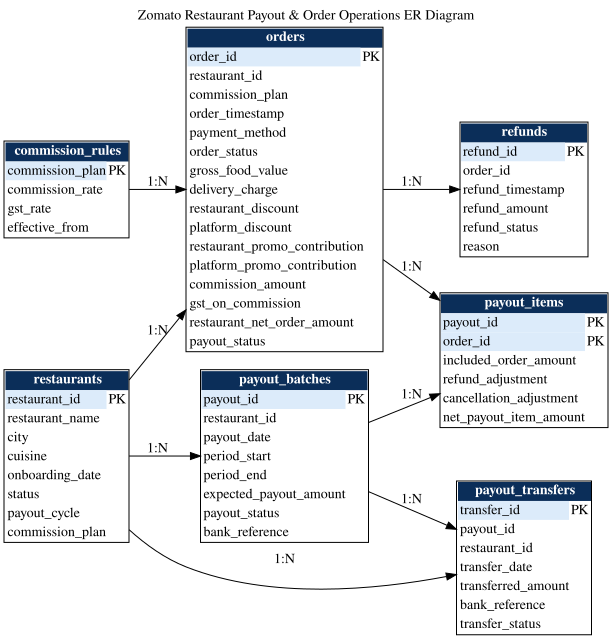

True

In [ ]:
# SQL DEVELOPER WORKSPACE - ER-1
# TODO: Complete all required table columns and relationships.
# Keep each column in the format: "column_name DATA_TYPE PK/FK/NOT NULL"

# SQL DEVELOPER WORKSPACE - ER-1

developer_tables = {
    "restaurants": [
        "restaurant_id TEXT PK NOT NULL", "restaurant_name TEXT NOT NULL", "city TEXT NOT NULL", "cuisine TEXT NOT NULL",
        "onboarding_date TEXT NOT NULL", "status TEXT NOT NULL", "payout_cycle TEXT NOT NULL", "commission_plan TEXT NOT NULL",
    ],
    "commission_rules": [
        "commission_plan TEXT PK NOT NULL", "commission_rate REAL NOT NULL",
        "gst_rate REAL NOT NULL", "effective_from TEXT NOT NULL",
    ],
    "orders": [
        "order_id TEXT PK NOT NULL", "restaurant_id TEXT FK NOT NULL", "commission_plan TEXT FK NOT NULL",
        "order_timestamp TEXT NOT NULL", "payment_method TEXT NOT NULL", "order_status TEXT NOT NULL",
        "gross_food_value REAL NOT NULL", "delivery_charge REAL NOT NULL", "restaurant_discount REAL NOT NULL",
        "platform_discount REAL NOT NULL", "restaurant_promo_contribution REAL NOT NULL",
        "platform_promo_contribution REAL NOT NULL", "commission_amount REAL NOT NULL",
        "gst_on_commission REAL NOT NULL", "restaurant_net_order_amount REAL NOT NULL",
        "payout_status TEXT NOT NULL",
    ],
    "refunds": [
        "refund_id TEXT PK NOT NULL", "order_id TEXT FK NOT NULL", "refund_timestamp TEXT NOT NULL",
        "refund_amount REAL NOT NULL", "refund_status TEXT NOT NULL", "reason TEXT NOT NULL",
    ],
    "payout_batches": [
        "payout_id TEXT PK NOT NULL", "restaurant_id TEXT FK NOT NULL", "payout_date TEXT NOT NULL",
        "period_start TEXT NOT NULL", "period_end TEXT NOT NULL", "expected_payout_amount REAL NOT NULL",
        "payout_status TEXT NOT NULL", "bank_reference TEXT NOT NULL",
    ],
    "payout_items": [
        "payout_id TEXT PK FK NOT NULL", "order_id TEXT PK FK NOT NULL", "included_order_amount REAL NOT NULL",
        "refund_adjustment REAL NOT NULL", "cancellation_adjustment REAL NOT NULL",
        "net_payout_item_amount REAL NOT NULL",
    ],
    "payout_transfers": [
        "transfer_id TEXT PK NOT NULL", "payout_id TEXT FK NOT NULL", "restaurant_id TEXT FK NOT NULL",
        "transfer_date TEXT NOT NULL", "transferred_amount REAL NOT NULL", "bank_reference TEXT NOT NULL",
        "transfer_status TEXT NOT NULL",
    ],
}
developer_relationships = [
    ("restaurants", "restaurant_id", "orders", "restaurant_id", "1:N"),
    ("commission_rules", "commission_plan", "orders", "commission_plan", "1:N"),
    ("orders", "order_id", "refunds", "order_id", "1:N"),
    ("restaurants", "restaurant_id", "payout_batches", "restaurant_id", "1:N"),
    ("payout_batches", "payout_id", "payout_items", "payout_id", "1:N"),
    ("orders", "order_id", "payout_items", "order_id", "1:N"),
    ("payout_batches", "payout_id", "payout_transfers", "payout_id", "1:N"),
    ("restaurants", "restaurant_id", "payout_transfers", "restaurant_id", "1:N"),
]
validate_and_draw_er(developer_tables, developer_relationships)

### Expected Output - ER-1

- `ER-1 | ... | Overall status: Passed`
- Seven connected table boxes
- Primary-key fields highlighted
- Eight relationship arrows
- Composite primary key in `payout_items`

**Hint:** Build master tables first, then orders/refunds, then payout and bridge/transfer tables.

# 3. API Operations

The temporary internal API is already running. The SQL Developer consumes the API using `requests`; API-server development is outside this work.

## API-Q1 - Filtered GET

**Business requirement - Restaurant Finance Platform Engineering:** Fetch exactly five completed UPI orders using `limit`, `payment_method`, and `order_status` parameters.

**How to approach:** Use the provided URL/payload/record ID, add only the required `requests` call or calls, keep the timeout, and run the validator.

In [ ]:
# SQL DEVELOPER WORKSPACE - API-Q1
api_q1_response = requests.get(
    f"{BASE_URL}/orders",
    params={"limit": 5, "payment_method": "UPI", "order_status": "COMPLETED"},
    timeout=5,
)
validate_api_q1(api_q1_response)

,order_id,restaurant_id,commission_plan,order_timestamp,payment_method,order_status,gross_food_value,delivery_charge,restaurant_discount,platform_discount,restaurant_promo_contribution,platform_promo_contribution,commission_amount,gst_on_commission,restaurant_net_order_amount,payout_status,cancelled_by,cancellation_reason,cancellation_compensation,created_at
0,ORD000011,RST031,PREMIUM,2026-07-25 16:23:33,UPI,COMPLETED,2189.12,30.0,20.0,60.0,0.0,25.0,327.87,59.02,1782.23,PENDING,,,0.0,2026-07-25 16:23:33
1,ORD000014,RST029,STANDARD,2026-07-10 14:12:25,UPI,COMPLETED,553.51,0.0,75.0,40.0,50.0,15.0,88.63,15.95,323.93,PENDING,,,0.0,2026-07-10 14:12:25
2,ORD000021,RST040,CLOUD_KITCHEN,2026-07-07 23:07:36,UPI,COMPLETED,2436.59,40.0,100.0,60.0,0.0,40.0,376.35,67.74,1892.50,PENDING,,,0.0,2026-07-07 23:07:36
3,ORD000028,RST003,PREMIUM,2026-07-26 00:00:15,UPI,COMPLETED,1020.47,60.0,20.0,40.0,0.0,25.0,150.07,27.01,823.39,PENDING,,,0.0,2026-07-26 00:00:15
4,ORD000041,RST040,CLOUD_KITCHEN,2026-07-30 09:24:20,UPI,COMPLETED,2264.51,30.0,0.0,120.0,0.0,60.0,362.32,65.22,1836.97,PENDING,,,0.0,2026-07-30 09:24:20


API-Q1 | HTTP=200 | records=5 | Overall status: Passed


### Expected Output - API-Q1

- HTTP status `200`
- Exactly `5` records
- Every record has `payment_method = UPI` and `order_status = COMPLETED`

**Hint:** Use `/orders` with `params` and a timeout.

## API-Q2 - Create an Order with POST

**Business requirement - Restaurant Finance Platform Engineering:** Create the provided order payload and confirm the returned record.

**How to approach:** Use the provided URL/payload/record ID, add only the required `requests` call or calls, keep the timeout, and run the validator.

In [ ]:
# SQL DEVELOPER WORKSPACE - API-Q2
reset_api_practice("POST")
new_order_payload = {
    "order_id": POST_ORDER_ID, "restaurant_id": "RST001", "commission_plan": "STANDARD", "order_timestamp": "2026-08-04 10:00:00",
    "payment_method": "UPI", "order_status": "PENDING", "gross_food_value": 850.0, "delivery_charge": 40.0,
    "restaurant_discount": 50.0, "platform_discount": 60.0, "restaurant_promo_contribution": 20.0, "platform_promo_contribution": 40.0,
    "commission_amount": 0.0, "gst_on_commission": 0.0, "restaurant_net_order_amount": 0.0, "payout_status": "NOT_ELIGIBLE",
    "cancelled_by": "", "cancellation_reason": "", "cancellation_compensation": 0.0, "created_at": "2026-08-04 10:00:00"
}
api_q2_response = requests.post(f"{BASE_URL}/orders", json=new_order_payload, timeout=5)
validate_api_q2(api_q2_response, new_order_payload)

,order_id,restaurant_id,commission_plan,order_timestamp,payment_method,order_status,gross_food_value,delivery_charge,restaurant_discount,platform_discount,restaurant_promo_contribution,platform_promo_contribution,commission_amount,gst_on_commission,restaurant_net_order_amount,payout_status,cancelled_by,cancellation_reason,cancellation_compensation,created_at
0,ORD-API-POST-001,RST001,STANDARD,2026-08-04 10:00:00,UPI,PENDING,850.0,40.0,50.0,60.0,20.0,40.0,0.0,0.0,0.0,NOT_ELIGIBLE,,,0.0,2026-08-04 10:00:00


API-Q2 | HTTP=201 | created_id=ORD-API-POST-001 | Overall status: Passed


### Expected Output - API-Q2

- HTTP status `201`
- Created ID `ORD-API-POST-001`
- Returned fields match the provided payload

**Hint:** Use `json=new_order_payload`.

## API-Q3 - Complete Replacement with PUT

**Business requirement - Restaurant Finance Platform Engineering:** Completely replace the reset practice order using the provided replacement payload.

**How to approach:** Use the provided URL/payload/record ID, add only the required `requests` call or calls, keep the timeout, and run the validator.

In [ ]:
# SQL DEVELOPER WORKSPACE - API-Q3
reset_api_practice("PUT")
replacement_payload = {
    "order_id": PUT_ORDER_ID, "restaurant_id": "RST002", "commission_plan": "GROWTH", "order_timestamp": "2026-08-04 11:00:00",
    "payment_method": "CARD", "order_status": "COMPLETED", "gross_food_value": 1250.0, "delivery_charge": 50.0,
    "restaurant_discount": 100.0, "platform_discount": 80.0, "restaurant_promo_contribution": 25.0, "platform_promo_contribution": 40.0,
    "commission_amount": 230.0, "gst_on_commission": 41.4, "restaurant_net_order_amount": 753.6, "payout_status": "BATCHED",
    "cancelled_by": "", "cancellation_reason": "", "cancellation_compensation": 0.0, "created_at": "2026-08-04 11:00:00"
}
api_q3_response = requests.put(f"{BASE_URL}/orders/{PUT_ORDER_ID}", json=replacement_payload, timeout=5)
validate_api_q3(api_q3_response, replacement_payload)

,order_id,restaurant_id,commission_plan,order_timestamp,payment_method,order_status,gross_food_value,delivery_charge,restaurant_discount,platform_discount,restaurant_promo_contribution,platform_promo_contribution,commission_amount,gst_on_commission,restaurant_net_order_amount,payout_status,cancelled_by,cancellation_reason,cancellation_compensation,created_at
0,ORD-API-PUT-001,RST002,GROWTH,2026-08-04 11:00:00,CARD,COMPLETED,1250.0,50.0,100.0,80.0,25.0,40.0,230.0,41.4,753.6,BATCHED,,,0.0,2026-08-04 11:00:00


API-Q3 | HTTP=200 | complete replacement=True | Overall status: Passed


### Expected Output - API-Q3

- HTTP status `200`
- Every replacement field matches `replacement_payload`
- No field from the baseline record survives unexpectedly

**Hint:** PUT uses the record-specific `/orders/{id}` endpoint.

## API-Q4 - Partial Update with PATCH

**Business requirement - Restaurant Finance Platform Engineering:** Update only `order_status` and `payout_status` for the reset practice order; all other fields must remain unchanged.

**How to approach:** Use the provided URL/payload/record ID, add only the required `requests` call or calls, keep the timeout, and run the validator.

In [ ]:
# SQL DEVELOPER WORKSPACE - API-Q4
api_q4_baseline = reset_api_practice("PATCH")
patch_payload = {"order_status": "COMPLETED", "payout_status": "BATCHED"}
api_q4_response = requests.patch(f"{BASE_URL}/orders/{PATCH_ORDER_ID}", json=patch_payload, timeout=5)
validate_api_q4(api_q4_response, api_q4_baseline, patch_payload)

,order_id,restaurant_id,commission_plan,order_timestamp,payment_method,order_status,gross_food_value,delivery_charge,restaurant_discount,platform_discount,restaurant_promo_contribution,platform_promo_contribution,commission_amount,gst_on_commission,restaurant_net_order_amount,payout_status,cancelled_by,cancellation_reason,cancellation_compensation,created_at
0,ORD-API-PATCH-001,RST001,STANDARD,2026-08-04 09:00:00,UPI,COMPLETED,600.0,40.0,0.0,40.0,0.0,20.0,0.0,0.0,0.0,BATCHED,,,0.0,2026-08-04 09:00:00


API-Q4 | HTTP=200 | targeted=True | untargeted=True | Overall status: Passed


### Expected Output - API-Q4

- HTTP status `200`
- Targeted fields change
- Untargeted fields remain equal to the reset baseline

**Hint:** PATCH sends only the fields that need to change.

## API-Q5 - GET -> DELETE -> GET Verification

**Business requirement - Restaurant Finance Platform Engineering:** Read the reset practice order, delete it, and read the same ID again to prove the 200 -> 200 -> 404 sequence.

**How to approach:** Use the provided URL/payload/record ID, add only the required `requests` call or calls, keep the timeout, and run the validator.

In [ ]:
# SQL DEVELOPER WORKSPACE - API-Q5
reset_api_practice("DELETE")
api_q5_read_before = requests.get(f"{BASE_URL}/orders/{DELETE_ORDER_ID}", timeout=5)
api_q5_delete = requests.delete(f"{BASE_URL}/orders/{DELETE_ORDER_ID}", timeout=5)
api_q5_read_after = requests.get(f"{BASE_URL}/orders/{DELETE_ORDER_ID}", timeout=5)
validate_api_q5(api_q5_read_before, api_q5_delete, api_q5_read_after)

,Request,HTTP status
0,GET before,200
1,DELETE,200
2,GET after,404


API-Q5 | sequence=[200, 200, 404] | Overall status: Passed


### Expected Output - API-Q5

| Request | Expected HTTP status |
|---|---:|
| GET before deletion | 200 |
| DELETE | 200 |
| GET after deletion | 404 |

**Hint:** Use the same record-specific URL for all three requests.

# 4. SQL Developer Questions

All business analysis in this section must be completed in SQL. Pandas is used only to display and validate SQL results.

## 4A. Foundations, Aggregations, and Multiple Tables

### Q1 - Largest Completed Restaurant Orders

**Business requirement - Restaurant Finance Operations:** List the ten completed orders with the highest restaurant net order amount so payout reviewers can inspect the largest restaurant earnings first.

**Tables to use:** `orders`, `restaurants`

**How to approach:**

- Join orders to restaurants.
- Filter completed orders.
- Sort by restaurant net order amount descending.
- Return ten rows with a stable order-ID tie-breaker.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q1
q1_sql = r"""
select o.order_id, r.restaurant_name, r.city, o.payment_method,
       o.gross_food_value, o.restaurant_net_order_amount, o.order_timestamp
from orders o
join restaurants r
    on r.restaurant_id = o.restaurant_id
where o.order_status = 'COMPLETED'
order by o.restaurant_net_order_amount desc, o.order_id
limit 10;
"""
q1 = run_developer_query("Q1", q1_sql)

,order_id,restaurant_name,city,payment_method,gross_food_value,restaurant_net_order_amount,order_timestamp
0,ORD000526,Wok Express 07,Mumbai,CARD,2474.34,2036.38,2026-07-01 04:00:13
1,ORD000085,Green Bowl 23,Delhi NCR,UPI,2457.02,2022.13,2026-07-28 16:46:35
2,ORD000826,Healthy Harvest 39,Hyderabad,CASH,2475.13,2012.34,2026-07-21 20:18:35
3,ORD000584,Spice Route 31,Bengaluru,UPI,2444.33,1991.68,2026-07-16 17:26:37
4,ORD000399,Spice Route 11,Bengaluru,UPI,2450.26,1990.10,2026-07-15 02:42:16
5,ORD000883,Tandoor Junction 36,Bengaluru,CASH,2470.38,1978.97,2026-07-24 01:23:50
6,ORD000799,Spice Route 11,Bengaluru,UPI,2398.53,1973.99,2026-07-29 17:55:57
7,ORD000550,Dessert Dock 40,Pune,UPI,2492.42,1971.85,2026-07-22 19:21:49
8,ORD000032,Royal Biryani 24,Hyderabad,CASH,2483.34,1965.15,2026-07-18 22:28:14
9,ORD000685,Healthy Harvest 19,Hyderabad,WALLET,2448.60,1954.05,2026-07-01 10:27:05


Columns: Passed | Row count: Passed | Stable first row: Passed | Full result: Passed
Q1 | Overall status: Passed


#### Expected Output - Q1

| Column | Requirement |
|---|---|
| `order_id` | Required output column |
| `restaurant_name` | Required output column |
| `city` | Required output column |
| `payment_method` | Required output column |
| `gross_food_value` | Required output column |
| `restaurant_net_order_amount` | Required output column |
| `order_timestamp` | Required output column |

**Expected row count:** `10`

**Stable first row after the required ordering:**

```text
| ORD000526 | Wok Express 07 | Mumbai | CARD | 2474.34 | 2036.38 | 2026-07-01 04:00:13 |
```

**Hint:** JOIN, WHERE, ORDER BY ... DESC, LIMIT

### Q2 - Restaurant Volume and Net-Value Thresholds

**Business requirement - Restaurant Finance Lead:** Find restaurants with at least 15 completed orders and more than INR 12,000 in completed restaurant net order value during the review period.

**Tables to use:** `orders`, `restaurants`

**How to approach:**

- Filter completed orders.
- Group by restaurant.
- Calculate order count, gross food value, and restaurant net value.
- Apply both thresholds with HAVING.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q2
q2_sql = r"""
select r.restaurant_id, r.restaurant_name, r.city,
       count(*) as completed_orders,
       round(sum(o.gross_food_value), 2) as gross_food_value,
       round(sum(o.restaurant_net_order_amount), 2) as net_order_value
from orders o
join restaurants r on r.restaurant_id = o.restaurant_id
where o.order_status = 'COMPLETED'
group by r.restaurant_id, r.restaurant_name, r.city
having count(*) >= 15 and sum(o.restaurant_net_order_amount) > 12000
order by net_order_value desc, r.restaurant_id;
"""
q2 = run_developer_query("Q2", q2_sql)

,restaurant_id,restaurant_name,city,completed_orders,gross_food_value,net_order_value
0,RST033,Green Bowl 33,Delhi NCR,38,47217.09,35838.12
1,RST028,Bake House 28,Delhi NCR,27,42666.93,33415.58
2,RST036,Tandoor Junction 36,Bengaluru,26,42398.29,33160.11
3,RST031,Spice Route 31,Bengaluru,25,38695.90,30601.72
4,RST040,Dessert Dock 40,Pune,25,38394.64,29987.29
...,...,...,...,...,...,...
32,RST035,Daily Dosa 35,Pune,18,20879.92,16396.81
33,RST023,Green Bowl 23,Delhi NCR,16,20220.38,15976.31
34,RST018,Bake House 18,Delhi NCR,17,20993.26,15482.06
35,RST013,Green Bowl 13,Delhi NCR,17,20217.90,15419.01


Columns: Passed | Row count: Passed | Stable first row: Passed | Full result: Passed
Q2 | Overall status: Passed


#### Expected Output - Q2

| Column | Requirement |
|---|---|
| `restaurant_id` | Required output column |
| `restaurant_name` | Required output column |
| `city` | Required output column |
| `completed_orders` | Required output column |
| `gross_food_value` | Required output column |
| `net_order_value` | Required output column |

**Expected row count:** `37`

**Stable first row after the required ordering:**

```text
| RST033 | Green Bowl 33 | Delhi NCR | 38 | 47217.09 | 35838.12 |
```

**Hint:** GROUP BY, COUNT, SUM, HAVING

### Q3 - Payout Batch and Transfer Reconciliation

**Business requirement - Payout Reconciliation Manager:** Reconcile every payout batch against successful transfer records and classify the batch as MATCHED, MISSING, or MISMATCHED using an INR 1.00 tolerance.

**Tables to use:** `payout_batches`, `payout_transfers`, `restaurants`

**How to approach:**

- Start from all payout batches.
- Join restaurant names.
- Left join transfer records.
- Aggregate transferred value and classify with COALESCE and CASE.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q3
q3_sql = r"""
select pb.payout_id, r.restaurant_name, pb.payout_date, pb.expected_payout_amount,
       coalesce(sum(case when pt.transfer_status = 'SUCCESS' then pt.transferred_amount end), 0) as transferred_amount,
       coalesce(sum(case when pt.transfer_status = 'SUCCESS' then pt.transferred_amount end), 0)
           - pb.expected_payout_amount as variance,
       case
         when count(case when pt.transfer_status = 'SUCCESS' then 1 end) = 0 then 'MISSING'
         when abs(coalesce(sum(case when pt.transfer_status = 'SUCCESS' then pt.transferred_amount end), 0)
                  - pb.expected_payout_amount) <= 1.00 then 'MATCHED'
         else 'MISMATCHED'
       end as reconciliation_status
from payout_batches pb
join restaurants r on r.restaurant_id = pb.restaurant_id
left join payout_transfers pt on pt.payout_id = pb.payout_id
group by pb.payout_id, r.restaurant_name, pb.payout_date, pb.expected_payout_amount
order by abs(variance) desc, pb.payout_id;
"""
q3 = run_developer_query("Q3", q3_sql)

,payout_id,restaurant_name,payout_date,expected_payout_amount,transferred_amount,variance,reconciliation_status
0,PAY-RST001-03,Spice Route 01,2026-07-23,10743.55,0.00,-10743.55,MISSING
1,PAY-RST001-02,Spice Route 01,2026-07-16,5573.81,0.00,-5573.81,MISSING
2,PAY-RST003-02,Green Bowl 03,2026-07-16,5182.03,0.00,-5182.03,MISSING
3,PAY-RST002-01,Urban Tadka 02,2026-07-09,4247.95,0.00,-4247.95,MISSING
4,PAY-RST002-04,Urban Tadka 02,2026-08-02,3466.30,0.00,-3466.30,MISSING
...,...,...,...,...,...,...,...
153,PAY-RST039-04,Healthy Harvest 39,2026-08-02,5741.93,5741.93,0.00,MATCHED
154,PAY-RST040-01,Dessert Dock 40,2026-07-09,6458.53,6458.53,0.00,MATCHED
155,PAY-RST040-02,Dessert Dock 40,2026-07-16,730.21,730.21,0.00,MATCHED
156,PAY-RST040-03,Dessert Dock 40,2026-07-23,5634.68,5634.68,0.00,MATCHED


Columns: Passed | Row count: Passed | Stable first row: Passed | Full result: Passed
Q3 | Overall status: Passed


#### Expected Output - Q3

| Column | Requirement |
|---|---|
| `payout_id` | Required output column |
| `restaurant_name` | Required output column |
| `payout_date` | Required output column |
| `expected_payout_amount` | Required output column |
| `transferred_amount` | Required output column |
| `variance` | Required output column |
| `reconciliation_status` | Required output column |

**Expected row count:** `158`

**Stable first row after the required ordering:**

```text
| PAY-RST001-03 | Spice Route 01 | 2026-07-23 | 10743.55 | 0.0 | -10743.55 | MISSING |
```

**Hint:** LEFT JOIN, COALESCE, SUM, COUNT, CASE

### Q4 - Payout Batches with No Transfer Record

**Business requirement - Restaurant Payout Operations:** Return payout batches that have no matching payout-transfer record so missing disbursements can be prioritized.

**Tables to use:** `payout_batches`, `payout_transfers`, `restaurants`

**How to approach:**

- Start with payout batches.
- Left join payout transfers.
- Keep rows where the transfer key is NULL.
- Sort by expected payout amount descending.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q4
q4_sql = r"""
select pb.payout_id, pb.restaurant_id, r.restaurant_name, pb.payout_date,
       pb.expected_payout_amount, pb.bank_reference
from payout_batches pb
join restaurants r on r.restaurant_id = pb.restaurant_id
left join payout_transfers pt on pt.payout_id = pb.payout_id
where pt.transfer_id is null
order by pb.expected_payout_amount desc, pb.payout_id;
"""
q4 = run_developer_query("Q4", q4_sql)

,payout_id,restaurant_id,restaurant_name,payout_date,expected_payout_amount,bank_reference
0,PAY-RST001-03,RST001,Spice Route 01,2026-07-23,10743.55,ZOM-PAY-RST001-03
1,PAY-RST001-02,RST001,Spice Route 01,2026-07-16,5573.81,ZOM-PAY-RST001-02
2,PAY-RST003-02,RST003,Green Bowl 03,2026-07-16,5182.03,ZOM-PAY-RST003-02
3,PAY-RST002-01,RST002,Urban Tadka 02,2026-07-09,4247.95,ZOM-PAY-RST002-01
4,PAY-RST002-04,RST002,Urban Tadka 02,2026-08-02,3466.30,ZOM-PAY-RST002-04
5,PAY-RST001-04,RST001,Spice Route 01,2026-08-02,3087.33,ZOM-PAY-RST001-04
6,PAY-RST002-02,RST002,Urban Tadka 02,2026-07-16,2504.81,ZOM-PAY-RST002-02
7,PAY-RST002-03,RST002,Urban Tadka 02,2026-07-23,2401.93,ZOM-PAY-RST002-03
8,PAY-RST003-01,RST003,Green Bowl 03,2026-07-09,2030.37,ZOM-PAY-RST003-01
9,PAY-RST001-01,RST001,Spice Route 01,2026-07-09,1529.22,ZOM-PAY-RST001-01


Columns: Passed | Row count: Passed | Stable first row: Passed | Full result: Passed
Q4 | Overall status: Passed


#### Expected Output - Q4

| Column | Requirement |
|---|---|
| `payout_id` | Required output column |
| `restaurant_id` | Required output column |
| `restaurant_name` | Required output column |
| `payout_date` | Required output column |
| `expected_payout_amount` | Required output column |
| `bank_reference` | Required output column |

**Expected row count:** `10`

**Stable first row after the required ordering:**

```text
| PAY-RST001-03 | RST001 | Spice Route 01 | 2026-07-23 | 10743.55 | ZOM-PAY-RST001-03 |
```

**Hint:** LEFT JOIN and WHERE right_table.key IS NULL

## 4B. Set Operations, Functions, Subqueries, and Standard CTEs

### Q5 - Restaurants with Refunds and Open Payout Exceptions

**Business requirement - Restaurant Finance Controls:** Identify restaurants that have both at least one completed refund and at least one open payout exception.

**Tables to use:** `orders`, `refunds`, `payout_exceptions`, `restaurants`

**How to approach:**

- Build a restaurant set from completed refunds.
- Build another restaurant set from open exceptions.
- Use INTERSECT.
- Return restaurant details in restaurant-ID order.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q5
q5_sql = r"""
select restaurant_id, restaurant_name, city, cuisine
from restaurants
where restaurant_id in (
    select o.restaurant_id
    from refunds rf
    join orders o on o.order_id = rf.order_id
    where rf.refund_status = 'COMPLETED'
    intersect
    select restaurant_id
    from payout_exceptions
    where status = 'OPEN'
)
order by restaurant_id;
"""
q5 = run_developer_query("Q5", q5_sql)

,restaurant_id,restaurant_name,city,cuisine
0,RST001,Spice Route 01,Bengaluru,Chinese
1,RST002,Urban Tadka 02,Mumbai,Healthy
2,RST003,Green Bowl 03,Delhi NCR,South Indian
3,RST004,Royal Biryani 04,Hyderabad,Fast Food
4,RST006,Tandoor Junction 06,Bengaluru,Biryani
...,...,...,...,...
23,RST033,Green Bowl 33,Delhi NCR,Chinese
24,RST035,Daily Dosa 35,Pune,South Indian
25,RST036,Tandoor Junction 36,Bengaluru,Fast Food
26,RST038,Bake House 38,Delhi NCR,Biryani


Columns: Passed | Row count: Passed | Stable first row: Passed | Full result: Passed
Q5 | Overall status: Passed


#### Expected Output - Q5

| Column | Requirement |
|---|---|
| `restaurant_id` | Required output column |
| `restaurant_name` | Required output column |
| `city` | Required output column |
| `cuisine` | Required output column |

**Expected row count:** `28`

**Stable first row after the required ordering:**

```text
| RST001 | Spice Route 01 | Bengaluru | Chinese |
```

**Hint:** INTERSECT inside an IN subquery

### Q6 - Restaurant Finance Risk View

**Business requirement - Restaurant Finance Controls:** Create a business-readable restaurant finance risk view using normalized display labels, date recency, open exception counts, and a CASE-based risk band.

**Tables to use:** `restaurants`, `orders`, `payout_exceptions`

**How to approach:**

- Aggregate latest order dates by restaurant.
- Aggregate open exception counts and severe exceptions.
- Use UPPER, SUBSTR, COALESCE, CAST, and date calculations.
- Assign HIGH, MEDIUM, or LOW with CASE.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q6
q6_sql = r"""
select
    r.restaurant_id,
    upper(r.restaurant_name) as restaurant_name_upper,
    substr(r.city, 1, 3) as city_code,

    cast(
        julianday('2026-08-05')
        - julianday(date(lo.last_order))
        as integer
    ) as days_since_last_completed_order,

    coalesce(ex.open_exceptions, 0) as open_exceptions,

    case
        when
            (
                julianday('2026-08-05')
                - julianday(date(lo.last_order))
            ) >= 10
            or coalesce(ex.open_exceptions, 0) >= 5
            or coalesce(ex.severe_exceptions, 0) >= 3
        then 'HIGH'

        when
            (
                julianday('2026-08-05')
                - julianday(date(lo.last_order))
            ) >= 7
            or coalesce(ex.open_exceptions, 0) >= 2
            or coalesce(ex.severe_exceptions, 0) >= 1
        then 'MEDIUM'

        else 'LOW'
    end as finance_risk_band

from restaurants r

left join (
    select
        restaurant_id,
        max(order_timestamp) as last_order
    from orders
    where order_status = 'COMPLETED'
    group by restaurant_id
) lo
    on lo.restaurant_id = r.restaurant_id

left join (
    select
        restaurant_id,
        count(*) as open_exceptions,
        sum(
            case
                when severity in ('HIGH', 'CRITICAL') then 1
                else 0
            end
        ) as severe_exceptions
    from payout_exceptions
    where status = 'OPEN'
    group by restaurant_id
) ex
    on ex.restaurant_id = r.restaurant_id

order by r.restaurant_id;
"""

q6 = run_developer_query("Q6", q6_sql)

,restaurant_id,restaurant_name_upper,city_code,days_since_last_completed_order,open_exceptions,finance_risk_band
0,RST001,SPICE ROUTE 01,Ben,5,9,HIGH
1,RST002,URBAN TADKA 02,Mum,5,7,HIGH
2,RST003,GREEN BOWL 03,Del,7,9,HIGH
3,RST004,ROYAL BIRYANI 04,Hyd,7,5,HIGH
4,RST005,DAILY DOSA 05,Pun,7,4,HIGH
...,...,...,...,...,...,...
35,RST036,TANDOOR JUNCTION 36,Ben,5,1,MEDIUM
36,RST037,WOK EXPRESS 37,Mum,6,0,LOW
37,RST038,BAKE HOUSE 38,Del,5,1,MEDIUM
38,RST039,HEALTHY HARVEST 39,Hyd,5,2,MEDIUM


Columns: Passed | Row count: Passed | Stable first row: Passed | Full result: Needs Review
Q6 | Overall status: Needs Review


#### Expected Output - Q6

| Column | Requirement |
|---|---|
| `restaurant_id` | Required output column |
| `restaurant_name_upper` | Required output column |
| `city_code` | Required output column |
| `days_since_last_completed_order` | Required output column |
| `open_exceptions` | Required output column |
| `finance_risk_band` | Required output column |

**Expected row count:** `40`

**Stable first row after the required ordering:**

```text
| RST001 | SPICE ROUTE 01 | Ben | 5 | 9 | HIGH |
```

**Hint:** UPPER, SUBSTR, julianday/date logic, COALESCE, CAST, CASE

### Q7 - Restaurants Above Network Average Order Value

**Business requirement - Restaurant Growth Finance:** Find restaurants whose average completed restaurant net order value is above the network-wide average for completed orders.

**Tables to use:** `orders`, `restaurants`

**How to approach:**

- Use a standard CTE to calculate each restaurant average.
- Use a scalar subquery for the network average.
- Join restaurant details.
- Sort highest average first.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q7
q7_sql = r"""
with rest_avg as (
    select restaurant_id, avg(restaurant_net_order_amount) as avg_val
    from orders
    where order_status = 'COMPLETED'
    group by restaurant_id
)
select r.restaurant_id, r.restaurant_name, r.city,
       round(a.avg_val, 2) as avg_completed_order_value
from rest_avg a
join restaurants r on r.restaurant_id = a.restaurant_id
where a.avg_val > (select avg(restaurant_net_order_amount)
                   from orders where order_status = 'COMPLETED')
order by avg_completed_order_value desc, r.restaurant_id;
"""
q7 = run_developer_query("Q7", q7_sql)

,restaurant_id,restaurant_name,city,avg_completed_order_value
0,RST036,Tandoor Junction 36,Bengaluru,1275.39
1,RST028,Bake House 28,Delhi NCR,1237.61
2,RST031,Spice Route 31,Bengaluru,1224.07
3,RST040,Dessert Dock 40,Pune,1199.49
4,RST003,Green Bowl 03,Delhi NCR,1186.46
...,...,...,...,...
16,RST025,Daily Dosa 25,Pune,1101.29
17,RST004,Royal Biryani 04,Hyderabad,1100.75
18,RST021,Spice Route 21,Bengaluru,1086.51
19,RST039,Healthy Harvest 39,Hyderabad,1079.43


Columns: Passed | Row count: Passed | Stable first row: Passed | Full result: Passed
Q7 | Overall status: Passed


#### Expected Output - Q7

| Column | Requirement |
|---|---|
| `restaurant_id` | Required output column |
| `restaurant_name` | Required output column |
| `city` | Required output column |
| `avg_completed_order_value` | Required output column |

**Expected row count:** `21`

**Stable first row after the required ordering:**

```text
| RST036 | Tandoor Junction 36 | Bengaluru | 1275.39 |
```

**Hint:** Standard CTE plus scalar subquery

### Q8 - Recalculate Payouts from Orders, Rules, and Refunds

**Business requirement - Payout Reconciliation Manager:** Recalculate each payout from commission rules and completed refunds, compare the recalculated amount with the recorded payout amount, and show the associated transferred value.

**Tables to use:** `orders`, `commission_rules`, `refunds`, `payout_items`, `payout_batches`, `payout_transfers`

**How to approach:**

- Aggregate completed refunds by order.
- Recalculate correct restaurant item value from order economics and commission rules.
- Aggregate corrected items by payout with standard CTEs.
- Compare recorded, recalculated, and transferred values.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q8
q8_sql = r"""
with refund_totals as (
    select order_id, sum(refund_amount) as refund_total
    from refunds
    where refund_status = 'COMPLETED'
    group by order_id
),
item_calc as (
    select pi.payout_id,
           round(max(0,
               (o.gross_food_value - o.restaurant_discount)
               - round((o.gross_food_value - o.restaurant_discount) * cr.commission_rate, 2)
               - round(round((o.gross_food_value - o.restaurant_discount) * cr.commission_rate, 2) * cr.gst_rate, 2)
               - o.restaurant_promo_contribution
               - coalesce(rt.refund_total, 0)
           ), 2) as correct_item_value
    from payout_items pi
    join orders o on o.order_id = pi.order_id
    join commission_rules cr on cr.commission_plan = o.commission_plan
    left join refund_totals rt on rt.order_id = pi.order_id
),
payout_calc as (
    select payout_id, round(sum(correct_item_value), 2) as recalculated_payout_amount
    from item_calc
    group by payout_id
),
transfer_totals as (
    select payout_id, sum(transferred_amount) as transferred_amount
    from payout_transfers
    where transfer_status = 'SUCCESS'
    group by payout_id
)
select pb.payout_id, pb.restaurant_id,
       pb.expected_payout_amount as recorded_payout_amount,
       pc.recalculated_payout_amount,
       coalesce(tt.transferred_amount, 0) as transferred_amount,
       round(pb.expected_payout_amount - pc.recalculated_payout_amount, 2) as calculation_variance,
       case when abs(pb.expected_payout_amount - pc.recalculated_payout_amount) <= 1.00
            then 'CALC_OK' else 'CALC_REVIEW' end as calculation_status
from payout_batches pb
join payout_calc pc on pc.payout_id = pb.payout_id
left join transfer_totals tt on tt.payout_id = pb.payout_id
order by abs(calculation_variance) desc, pb.payout_id;
"""
q8 = run_developer_query("Q8", q8_sql)

,payout_id,restaurant_id,recorded_payout_amount,recalculated_payout_amount,transferred_amount,calculation_variance,calculation_status
0,PAY-RST001-03,RST001,10743.55,10722.55,0.00,21.0,CALC_REVIEW
1,PAY-RST002-01,RST002,4247.95,4233.95,0.00,14.0,CALC_REVIEW
2,PAY-RST002-02,RST002,2504.81,2497.81,0.00,7.0,CALC_REVIEW
3,PAY-RST003-01,RST003,2030.37,2023.37,0.00,7.0,CALC_REVIEW
4,PAY-RST003-03,RST003,5220.41,5213.41,5245.41,7.0,CALC_REVIEW
...,...,...,...,...,...,...,...
153,PAY-RST039-04,RST039,5741.93,5741.93,5741.93,0.0,CALC_OK
154,PAY-RST040-01,RST040,6458.53,6458.53,6458.53,0.0,CALC_OK
155,PAY-RST040-02,RST040,730.21,730.21,730.21,0.0,CALC_OK
156,PAY-RST040-03,RST040,5634.68,5634.68,5634.68,0.0,CALC_OK


Columns: Passed | Row count: Passed | Stable first row: Passed | Full result: Passed
Q8 | Overall status: Passed


#### Expected Output - Q8

| Column | Requirement |
|---|---|
| `payout_id` | Required output column |
| `restaurant_id` | Required output column |
| `recorded_payout_amount` | Required output column |
| `recalculated_payout_amount` | Required output column |
| `transferred_amount` | Required output column |
| `calculation_variance` | Required output column |
| `calculation_status` | Required output column |

**Expected row count:** `158`

**Stable first row after the required ordering:**

```text
| PAY-RST001-03 | RST001 | 10743.55 | 10722.55 | 0.0 | 21.0 | CALC_REVIEW |
```

**Hint:** Multiple non-recursive CTEs, JOINs, COALESCE, CASE

## 4C. Window Functions

### Q9 - Restaurant Net-Value Ranking Within City

**Business requirement - City Finance Manager:** Rank restaurants by completed restaurant net order value within each city while preserving ties.

**Tables to use:** `orders`, `restaurants`

**How to approach:**

- Aggregate completed net value per restaurant.
- Partition rankings by city.
- Rank highest net value first.
- Return all restaurants.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q9
q9_sql = r"""
select restaurant_id, restaurant_name, city, completed_net_value,
       rank() over (partition by city order by completed_net_value desc) as city_rank
from (
    select r.restaurant_id, r.restaurant_name, r.city,
           round(coalesce(sum(case when o.order_status = 'COMPLETED'
                                   then o.restaurant_net_order_amount end), 0), 2) as completed_net_value
    from restaurants r
    left join orders o on o.restaurant_id = r.restaurant_id
    group by r.restaurant_id, r.restaurant_name, r.city
) t
order by city, city_rank, restaurant_id;
"""
q9 = run_developer_query("Q9", q9_sql)

,restaurant_id,restaurant_name,city,completed_net_value,city_rank
0,RST036,Tandoor Junction 36,Bengaluru,33160.11,1
1,RST031,Spice Route 31,Bengaluru,30601.72,2
2,RST011,Spice Route 11,Bengaluru,28362.52,3
3,RST026,Tandoor Junction 26,Bengaluru,26189.69,4
4,RST001,Spice Route 01,Bengaluru,23202.31,5
...,...,...,...,...,...
35,RST030,Dessert Dock 30,Pune,21838.92,4
36,RST005,Daily Dosa 05,Pune,19417.56,5
37,RST025,Daily Dosa 25,Pune,18721.98,6
38,RST035,Daily Dosa 35,Pune,16396.81,7


Columns: Passed | Row count: Passed | Stable first row: Passed | Full result: Passed
Q9 | Overall status: Passed


#### Expected Output - Q9

| Column | Requirement |
|---|---|
| `restaurant_id` | Required output column |
| `restaurant_name` | Required output column |
| `city` | Required output column |
| `completed_net_value` | Required output column |
| `city_rank` | Required output column |

**Expected row count:** `40`

**Stable first row after the required ordering:**

```text
| RST036 | Tandoor Junction 36 | Bengaluru | 33160.11 | 1 |
```

**Hint:** RANK() OVER (PARTITION BY ... ORDER BY ...)

### Q10 - Daily Running Net Value and Seven-Day Moving Average

**Business requirement - Restaurant Finance Planning:** Produce a daily completed restaurant net-value series with a cumulative running total and a seven-day moving average.

**Tables to use:** `orders`

**How to approach:**

- Aggregate completed net value by order date.
- Use a cumulative SUM window.
- Use a seven-row AVG window.
- Sort chronologically.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q10
q10_sql = r"""
with daily as (
    select date(order_timestamp) as order_date,
           round(sum(restaurant_net_order_amount), 2) as daily_net_value
    from orders
    where order_status = 'COMPLETED'
    group by date(order_timestamp)
)
select order_date, daily_net_value,
       round(sum(daily_net_value) over (order by order_date), 2) as running_net_value,
       round(avg(daily_net_value) over (order by order_date
             rows between 6 preceding and current row), 2) as seven_day_moving_average
from daily
order by order_date;
"""
q10 = run_developer_query("Q10", q10_sql)

,order_date,daily_net_value,running_net_value,seven_day_moving_average
0,2026-07-01,29153.68,29153.68,29153.68
1,2026-07-02,34243.32,63397.00,31698.50
2,2026-07-03,29431.32,92828.32,30942.77
3,2026-07-04,32087.34,124915.66,31228.92
4,2026-07-05,22712.27,147627.93,29525.59
...,...,...,...,...
26,2026-07-27,24967.31,741719.87,27396.27
27,2026-07-28,29690.18,771410.05,26658.94
28,2026-07-29,34785.37,806195.42,28363.39
29,2026-07-30,34344.32,840539.74,29599.95


Columns: Passed | Row count: Passed | Stable first row: Passed | Full result: Passed
Q10 | Overall status: Passed


#### Expected Output - Q10

| Column | Requirement |
|---|---|
| `order_date` | Required output column |
| `daily_net_value` | Required output column |
| `running_net_value` | Required output column |
| `seven_day_moving_average` | Required output column |

**Expected row count:** `31`

**Stable first row after the required ordering:**

```text
| 2026-07-01 | 29153.68 | 29153.68 | 29153.68 |
```

**Hint:** SUM/AVG window frames with ROWS BETWEEN

### Q11 - Day-over-Day Restaurant Net-Value Change

**Business requirement - Restaurant Finance Planning:** Compare each day of completed restaurant net value with the previous day and calculate a safe percentage change.

**Tables to use:** `orders`

**How to approach:**

- Aggregate daily net value.
- Use LAG for the previous day.
- Calculate absolute change.
- Avoid division when the previous value is NULL or zero.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q11
q11_sql = r"""
with daily as (
    select date(order_timestamp) as order_date,
           round(sum(restaurant_net_order_amount), 2) as daily_net_value
    from orders
    where order_status = 'COMPLETED'
    group by date(order_timestamp)
),
lagged as (
    select order_date, daily_net_value,
           lag(daily_net_value) over (order by order_date) as previous_day_value
    from daily
)
select order_date, daily_net_value, previous_day_value,
       round(daily_net_value - previous_day_value, 2) as day_over_day_change,
       case when previous_day_value is null or previous_day_value = 0 then null
            else round((daily_net_value - previous_day_value) * 100.0 / previous_day_value, 2)
       end as day_over_day_pct
from lagged
order by order_date;
"""
q11 = run_developer_query("Q11", q11_sql)

,order_date,daily_net_value,previous_day_value,day_over_day_change,day_over_day_pct
0,2026-07-01,29153.68,NaN,NaN,NaN
1,2026-07-02,34243.32,29153.68,5089.64,17.46
2,2026-07-03,29431.32,34243.32,-4812.00,-14.05
3,2026-07-04,32087.34,29431.32,2656.02,9.02
4,2026-07-05,22712.27,32087.34,-9375.07,-29.22
...,...,...,...,...,...
26,2026-07-27,24967.31,21519.67,3447.64,16.02
27,2026-07-28,29690.18,24967.31,4722.87,18.92
28,2026-07-29,34785.37,29690.18,5095.19,17.16
29,2026-07-30,34344.32,34785.37,-441.05,-1.27


Columns: Passed | Row count: Passed | Stable first row: Passed | Full result: Passed
Q11 | Overall status: Passed


#### Expected Output - Q11

| Column | Requirement |
|---|---|
| `order_date` | Required output column |
| `daily_net_value` | Required output column |
| `previous_day_value` | Required output column |
| `day_over_day_change` | Required output column |
| `day_over_day_pct` | Required output column |

**Expected row count:** `31`

**Stable first row after the required ordering:**

```text
| 2026-07-01 | 29153.68 | NULL | NULL | NULL |
```

**Hint:** LAG, CASE, arithmetic and safe percentage calculation

### Q12 - First and Latest Completed Order per Restaurant

**Business requirement - Restaurant Operations Analytics:** Return each restaurant's first and latest completed order IDs and timestamps for operating-history checks.

**Tables to use:** `orders`, `restaurants`

**How to approach:**

- Use ROW_NUMBER twice within each restaurant.
- Rank ascending for first and descending for latest.
- Use conditional aggregation to put both records on one row.
- Retain every restaurant.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q12
q12_sql = r"""
with ranked as (
    select restaurant_id, order_id, order_timestamp,
           row_number() over (partition by restaurant_id order by order_timestamp asc, order_id asc) as rn_first,
           row_number() over (partition by restaurant_id order by order_timestamp desc, order_id desc) as rn_last
    from orders
    where order_status = 'COMPLETED'
)
select r.restaurant_id, r.restaurant_name,
       max(case when k.rn_first = 1 then k.order_id end) as first_completed_order_id,
       max(case when k.rn_first = 1 then k.order_timestamp end) as first_completed_order_timestamp,
       max(case when k.rn_last = 1 then k.order_id end) as latest_completed_order_id,
       max(case when k.rn_last = 1 then k.order_timestamp end) as latest_completed_order_timestamp
from restaurants r
left join ranked k on k.restaurant_id = r.restaurant_id
group by r.restaurant_id, r.restaurant_name
order by r.restaurant_id;
"""
q12 = run_developer_query("Q12", q12_sql)

,restaurant_id,restaurant_name,first_completed_order_id,first_completed_order_timestamp,latest_completed_order_id,latest_completed_order_timestamp
0,RST001,Spice Route 01,ORD000564,2026-07-02 08:23:11,ORD000033,2026-07-31 19:25:20
1,RST002,Urban Tadka 02,ORD000955,2026-07-01 14:28:47,ORD000611,2026-07-31 22:53:18
2,RST003,Green Bowl 03,ORD000068,2026-07-06 10:28:23,ORD000421,2026-07-29 17:50:21
3,RST004,Royal Biryani 04,ORD000982,2026-07-01 06:17:08,ORD000353,2026-07-29 20:46:24
4,RST005,Daily Dosa 05,ORD000109,2026-07-01 11:55:04,ORD000915,2026-07-29 21:57:11
...,...,...,...,...,...,...
35,RST036,Tandoor Junction 36,ORD000547,2026-07-01 10:54:47,ORD000846,2026-07-31 09:15:21
36,RST037,Wok Express 37,ORD000572,2026-07-01 22:00:28,ORD000659,2026-07-30 14:22:52
37,RST038,Bake House 38,ORD000369,2026-07-01 16:54:50,ORD000616,2026-07-31 13:46:41
38,RST039,Healthy Harvest 39,ORD000463,2026-07-01 03:26:03,ORD000643,2026-07-31 06:38:01


Columns: Passed | Row count: Passed | Stable first row: Passed | Full result: Passed
Q12 | Overall status: Passed


#### Expected Output - Q12

| Column | Requirement |
|---|---|
| `restaurant_id` | Required output column |
| `restaurant_name` | Required output column |
| `first_completed_order_id` | Required output column |
| `first_completed_order_timestamp` | Required output column |
| `latest_completed_order_id` | Required output column |
| `latest_completed_order_timestamp` | Required output column |

**Expected row count:** `40`

**Stable first row after the required ordering:**

```text
| RST001 | Spice Route 01 | ORD000564 | 2026-07-02 08:23:11 | ORD000033 | 2026-07-31 19:25:20 |
```

**Hint:** ROW_NUMBER plus conditional aggregation

### Q13 - Top Three Exception Ranks per City with Ties

**Business requirement - Restaurant Finance Controls:** Within each city, rank restaurant-and-exception combinations by open exception count and return the top three ranks while preserving ties.

**Tables to use:** `payout_exceptions`, `restaurants`

**How to approach:**

- Count open exceptions by city, restaurant, and exception type.
- Use DENSE_RANK within each city.
- Keep ranks one through three.
- Sort by city, rank, restaurant, and exception type.

In [ ]:
# SQL DEVELOPER WORKSPACE - Q13
q13_sql = r"""
with counts as (
    select r.city, e.restaurant_id, e.exception_type, count(*) as exception_count
    from payout_exceptions e
    join restaurants r on r.restaurant_id = e.restaurant_id
    where e.status = 'OPEN'
    group by r.city, e.restaurant_id, e.exception_type
),
ranked as (
    select city, restaurant_id, exception_type, exception_count,
           dense_rank() over (partition by city order by exception_count desc) as exception_rank
    from counts
)
select city, restaurant_id, exception_type, exception_count, exception_rank
from ranked
where exception_rank <= 3
order by city, exception_rank, restaurant_id, exception_type;
"""
q13 = run_developer_query("Q13", q13_sql)

,city,restaurant_id,exception_type,exception_count,exception_rank
0,Bengaluru,RST001,MISSING_PAYOUT_TRANSFER,4,1
1,Bengaluru,RST001,REFUND_DEDUCTION_MISMATCH,3,2
2,Bengaluru,RST031,OVERDUE_UNPAID_ORDER,3,2
3,Bengaluru,RST006,COMMISSION_RULE_MISMATCH,2,3
4,Bengaluru,RST006,LATE_PAYOUT_TRANSFER,2,3
...,...,...,...,...,...
37,Mumbai,RST027,OVERDUE_UNPAID_ORDER,1,3
38,Pune,RST005,PAYOUT_AMOUNT_MISMATCH,4,1
39,Pune,RST040,OVERDUE_UNPAID_ORDER,3,2
40,Pune,RST010,DUPLICATE_TRANSFER_REFERENCE,2,3


Columns: Passed | Row count: Passed | Stable first row: Passed | Full result: Passed
Q13 | Overall status: Passed


#### Expected Output - Q13

| Column | Requirement |
|---|---|
| `city` | Required output column |
| `restaurant_id` | Required output column |
| `exception_type` | Required output column |
| `exception_count` | Required output column |
| `exception_rank` | Required output column |

**Expected row count:** `42`

**Stable first row after the required ordering:**

```text
| Bengaluru | RST001 | MISSING_PAYOUT_TRANSFER | 4 | 1 |
```

**Hint:** DENSE_RANK() with PARTITION BY and filtering

# 5. Transaction Management

## T1 - Approved Payout Adjustment with COMMIT

**Business requirement - Restaurant Finance Lead:** Post an approved INR 250 payout correction to restaurant `RST001` in one explicit transaction.

**Table to use:** `restaurant_ledger`

**How to approach:** Begin the transaction, insert the provided ledger record, and commit it. The validator resets this activity record before each run and proves that the committed row remains.

In [ ]:
# SQL DEVELOPER WORKSPACE - T1
transaction_t1_sql = r"""
BEGIN;
INSERT INTO restaurant_ledger (ledger_id, restaurant_id, source_type, source_id, entry_timestamp, amount, entry_status, description)
VALUES ('LED-ZOM-COMMIT-001', 'RST001', 'PAYOUT_ADJUSTMENT', 'ADJ-COMMIT-001', '2026-08-05 09:00:00', 250.00, 'POSTED', 'Approved payout correction');
COMMIT;
"""
execute_transaction_activity("T1", transaction_t1_sql, "LED-ZOM-COMMIT-001", should_exist=True)

T1 | Actual row present: True | Expected row present: True | Overall status: Passed


,ledger_id,restaurant_id,source_type,source_id,entry_timestamp,amount,entry_status,description
0,LED-ZOM-COMMIT-001,RST001,PAYOUT_ADJUSTMENT,ADJ-COMMIT-001,2026-08-05 09:00:00,250.0,POSTED,Approved payout correction


### Expected Output - T1

- `Actual row present: True`
- `Expected row present: True`
- `Overall status: Passed`

**Hint:** `BEGIN`, `INSERT`, and `COMMIT` must all appear in the transaction script.

## T2 - Temporary Deduction with ROLLBACK

**Business requirement - Restaurant Finance Controls:** Test an unapproved INR 100 temporary deduction for restaurant `RST002`, then roll it back so it never remains in the ledger.

**Table to use:** `restaurant_ledger`

**How to approach:** Begin the transaction, insert the temporary ledger row, and roll back. The validator proves that the row is absent afterward.

In [ ]:
# SQL DEVELOPER WORKSPACE - T2
transaction_t2_sql = r"""
BEGIN;
INSERT INTO restaurant_ledger (ledger_id, restaurant_id, source_type, source_id, entry_timestamp, amount, entry_status, description)
VALUES ('LED-ZOM-ROLLBACK-001', 'RST002', 'TEMP_DEDUCTION', 'ADJ-ROLLBACK-001', '2026-08-05 09:05:00', -100.00, 'PENDING', 'Unapproved temporary deduction');
ROLLBACK;
"""
execute_transaction_activity("T2", transaction_t2_sql, "LED-ZOM-ROLLBACK-001", should_exist=False)

T2 | Actual row present: False | Expected row present: False | Overall status: Passed


### Expected Output - T2

- `Actual row present: False`
- `Expected row present: False`
- `Overall status: Passed`

**Hint:** `BEGIN`, `INSERT`, and `ROLLBACK` must all appear in the transaction script.

# 6. Workflow Automation

## AUTO-FLOW - Seven-Step Payout Summary Workflow

**Business requirement - Engineering Manager:** Define exactly seven ordered steps for the scheduled payout-summary process, from scheduler trigger through monitoring.

The required concepts are: scheduler/cron trigger -> internal API call -> HTTP and schema validation -> raw JSON storage -> SQLite loading -> SQL report generation -> logging/monitoring.

AUTO-FLOW | step count=7 | concept/order checks=7/7 | Overall status: Passed


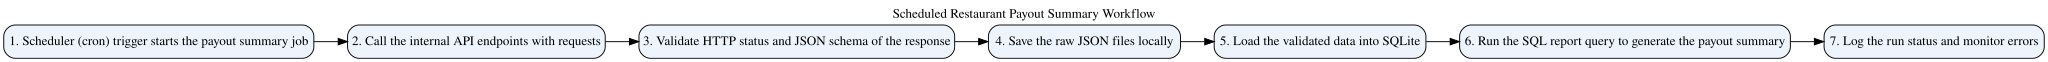

True

In [ ]:
# SQL DEVELOPER WORKSPACE - AUTO-FLOW
automation_steps = [
    "Scheduler (cron) trigger starts the payout summary job",
    "Call the internal API endpoints with requests",
    "Validate HTTP status and JSON schema of the response",
    "Save the raw JSON files locally",
    "Load the validated data into SQLite",
    "Run the SQL report query to generate the payout summary",
    "Log the run status and monitor errors",
]
_validate_ordered_steps("AUTO-FLOW", automation_steps, AUTO_FLOW_CONCEPTS, "Scheduled Restaurant Payout Summary Workflow")

### Expected Output - AUTO-FLOW

- Exactly seven validated ordered steps
- `Overall status: Passed`
- A visible left-to-right payout-summary workflow diagram

**Hint:** Keep one required concept per step and preserve the required order.

## AUTO-REPORT - Scheduled Open-Exception Summary

**Business requirement - Restaurant Finance Operations:** Write the SQL report that a scheduled workflow would run to summarize open payout exceptions by exception type and severity.

**Tables to use:** `payout_exceptions`

**How to approach:** Filter open exceptions, group by exception type and severity, count exceptions, total expected/actual values, and order critical issues first.

In [ ]:
# SQL DEVELOPER WORKSPACE - AUTO-REPORT
auto_report_sql = r"""
select exception_type, severity,
       count(*) as open_exception_count,
       round(coalesce(sum(expected_value), 0), 2) as total_expected_value,
       round(coalesce(sum(actual_value), 0), 2) as total_actual_value
from payout_exceptions
where status = 'OPEN'
group by exception_type, severity
order by case severity when 'CRITICAL' then 1 when 'HIGH' then 2 when 'MEDIUM' then 3 else 4 end,
         open_exception_count desc, exception_type;
"""
auto_report = validate_auto_report(auto_report_sql)

,exception_type,severity,open_exception_count,total_expected_value,total_actual_value
0,MISSING_PAYOUT_TRANSFER,CRITICAL,10,40767.30,0.00
1,DUPLICATE_TRANSFER_REFERENCE,CRITICAL,4,4.00,8.00
2,OVERDUE_UNPAID_ORDER,HIGH,45,43183.12,0.00
3,PAYOUT_AMOUNT_MISMATCH,HIGH,12,63571.45,63613.45
4,REFUND_DEDUCTION_MISMATCH,HIGH,8,2817.23,2761.23
5,COMMISSION_RULE_MISMATCH,MEDIUM,18,3967.02,4012.02
6,LATE_PAYOUT_TRANSFER,MEDIUM,9,18.00,36.00


AUTO-REPORT | Overall status: Passed


### Expected Output - AUTO-REPORT

| Column | Requirement |
|---|---|
| `exception_type` | Required output column |
| `severity` | Required output column |
| `open_exception_count` | Required output column |
| `total_expected_value` | Required output column |
| `total_actual_value` | Required output column |

**Expected row count:** `7`

**Stable first row:**

```text
| MISSING_PAYOUT_TRANSFER | CRITICAL | 10 | 40767.3 | 0.0 |
```

**Hint:** `WHERE`, `GROUP BY`, `COUNT`, `SUM`, `COALESCE`, and severity-aware ordering.

## AUTO-CRON - Cron Expressions

Provide four five-field cron expressions for the operational schedules below. The expressions are cron-ready; a Google Colab runtime cannot remain active as a permanent scheduler after the runtime stops.

In [ ]:
# SQL DEVELOPER WORKSPACE - AUTO-CRON
cron_answers = {
    'Daily at 8 AM, 12 PM, and 4 PM': '0 8,12,16 * * *',
    'Every weekday at 5 PM': '0 17 * * 1-5',
    'Every day at midnight': '0 0 * * *',
    'Every Sunday at 2 AM': '0 2 * * 0',
}
validate_cron(cron_answers)

,Scenario,Cron expression,Status
0,"Daily at 8 AM, 12 PM, and 4 PM","0 8,12,16 * * *",Passed
1,Every weekday at 5 PM,0 17 * * 1-5,Passed
2,Every day at midnight,0 0 * * *,Passed
3,Every Sunday at 2 AM,0 2 * * 0,Passed


AUTO-CRON | Overall status: Passed


### Expected Output - AUTO-CRON

| Scenario | Expected expression |
|---|---|
| Daily at 8 AM, 12 PM, and 4 PM | `0 8,12,16 * * *` |
| Every weekday at 5 PM | `0 17 * * 1-5` |
| Every day at midnight | `0 0 * * *` |
| Every Sunday at 2 AM | `0 2 * * 0` |

The Instructor Solution must display four `Passed` rows.

# 7. Engineering Practices

## ENG-GIT - Git Collaboration Workflow

**Business requirement - Engineering Manager:** Enter the eight ordered collaboration steps used to deliver a reviewed SQL change. No Git command execution or repository creation is required.

ENG-GIT | step count=8 | concept/order checks=8/8 | Overall status: Passed


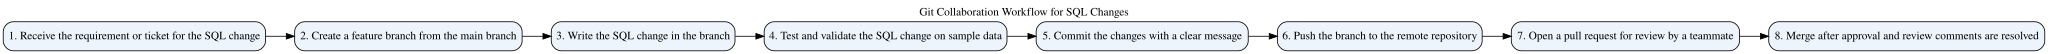

True

In [ ]:
# SQL DEVELOPER WORKSPACE - ENG-GIT
git_steps = [
    "Receive the requirement or ticket for the SQL change",
    "Create a feature branch from the main branch",
    "Write the SQL change in the branch",
    "Test and validate the SQL change on sample data",
    "Commit the changes with a clear message",
    "Push the branch to the remote repository",
    "Open a pull request for review by a teammate",
    "Merge after approval and review comments are resolved",
]
_validate_ordered_steps("ENG-GIT", git_steps, GIT_CONCEPTS, "Git Collaboration Workflow for SQL Changes")

### Expected Output - ENG-GIT

- Exactly eight ordered steps
- Required collaboration concepts validated in order
- `Overall status: Passed`
- Visible Git collaboration workflow diagram

## ENG-CHANGE - Safe Database-Change Workflow

**Business requirement - Engineering Manager:** Enter the eight ordered controls used to make a safe database change, including backup/rollback planning, development testing, peer review, deployment monitoring, and rollback on failure.

ENG-CHANGE | step count=8 | concept/order checks=8/8 | Overall status: Passed


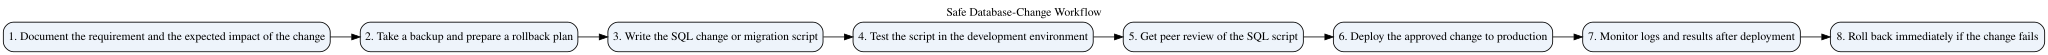

True

In [ ]:
# SQL DEVELOPER WORKSPACE - ENG-CHANGE
change_steps = [
    "Document the requirement and the expected impact of the change",
    "Take a backup and prepare a rollback plan",
    "Write the SQL change or migration script",
    "Test the script in the development environment",
    "Get peer review of the SQL script",
    "Deploy the approved change to production",
    "Monitor logs and results after deployment",
    "Roll back immediately if the change fails",
]
_validate_ordered_steps("ENG-CHANGE", change_steps, CHANGE_CONCEPTS, "Safe Database-Change Workflow")

### Expected Output - ENG-CHANGE

- Exactly eight ordered steps
- Required safe-change concepts validated in order
- `Overall status: Passed`
- Visible safe database-change workflow diagram

# 8. Progress Check

The dashboard below lists all 26 validated activities. A completed Instructor Solution must show every activity as **Passed**. In the Developer notebook, unanswered workspaces remain **Needs Review** until completed.

In [ ]:
progress = show_progress()
print(f"Validated activities: {len(progress)} | Passed: {(progress['Status']=='Passed').sum()} | Needs Review: {(progress['Status']=='Needs Review').sum()}")

,Activity ID,Status
0,ER-1,Passed
1,API-Q1,Passed
2,API-Q2,Passed
3,API-Q3,Passed
4,API-Q4,Passed
...,...,...
21,AUTO-FLOW,Passed
22,AUTO-REPORT,Passed
23,AUTO-CRON,Passed
24,ENG-GIT,Passed


,Status,Count
0,Passed,25
1,Needs Review,1


Validated activities: 26 | Passed: 25 | Needs Review: 1
